# Experiments 8 & 9 — Effect of Attention Type and Attention Position in a Pretrained ResNet50
**CS3807 Deep Learning Laboratory · Shiv Nadar University Chennai**

This notebook implements *every* requirement of `Experiment_8.tex` on **TensorFlow Flowers (`tf_flowers`)** with a single backbone, **ResNet50 (ImageNet)**.

### Run order
Run the cells **top to bottom**. Training cells are grouped by experiment and are **resumable**: each trained model stores its weights, metrics, history and test-set probabilities under `OUT_DIR` (Google Drive if mounted). If Colab disconnects, reconnect, re-run the setup cells and re-run the training cells — finished models are skipped automatically.

### Experiment map (spec section → model names)
| Spec | Experiment | Models trained |
|---|---|---|
| §14 | Exp 1 – attention type @ P3 | `A0` baseline, `A1` channel, `A2` spatial, `A3` channel→spatial, `A4` self-attention, `A5` channel→spatial→self |
| §15 | Exp 2 – attention position (C→S) | `B1` P1, `B2` P2, `B3` = `A3` (P3), `B4` P4 |
| §16 | Exp 3 – multiple positions | `A3` (P3), `B4` (P4), `M34` (P3+P4), `M234` (P2+P3+P4, extended) |
| §17 | Exp 4 – attention order | `A3` (C→S) vs `O1` (S→C) at P3 |
| §18 | Exp 5 – spatial kernel size | `K3` (3×3), `K5` (5×5), `A3` (7×7) |
| §19, §36 | Additional mechanisms @ P3 | ECA, CBAM, Coordinate Attention (+ SE ≡ `A1`, self-attention ≡ `A4`) |

### Design decisions (stated explicitly so nothing is hidden)
1. **SE ≡ channel attention.** The channel-attention block defined in §9 (GAP → FC(C/r) → ReLU → FC(C) → sigmoid) *is* the Squeeze-and-Excitation block, so `A1` is reported as "Channel / SE" (the spec's own §19.1 table also has a single "Channel / SE" row). ECA, CBAM and Coordinate Attention are the three additional mechanisms.
2. **`A5` combined attention** is applied sequentially: channel → spatial → self-attention.
3. **Self-attention** is the lightweight non-local form: Q,K have `d=C/8` channels, V has `C/2` channels, followed by a bias-free output projection and the learnable residual scale γ (initialised to 0), exactly `F_SA = F + γ·reshape(AV)`.
4. **Reuse instead of duplicate runs.** `B3` is the same configuration as `A3`, and the `k=7` entry of Exp 5 is also `A3`, so these are one training run each (this also guarantees the comparisons are exactly controlled).
5. **Exp 5 uses the channel→spatial module at P3** (the principal module of the experiment); only the spatial kernel changes.
6. **Controlled protocol (identical for all models):** same 70/15/15 split, preprocessing, augmentation, seed, optimiser (Adam), batch size, epochs, LR schedule, fine-tuning (conv5_x unfrozen), classifier and metrics.
7. **Single run per configuration.** To avoid over-reading small differences, every accuracy has a 95 % bootstrap CI and a paired exact McNemar test against the baseline.
8. **Grad-CAM** is computed from gradients of the class logit w.r.t. the final feature map (`final_features`, the tensor fed to GAP). It is a *post-hoc explanation*, **not** an internal attention map.

In [1]:
# No extra installs are needed: TensorFlow, NumPy, SciPy, scikit-learn, pandas and Matplotlib are preinstalled on Colab.
# (The dataset is downloaded directly from the official TensorFlow storage, so the fragile `tensorflow-datasets` package is not used.)
  # harmless safety net: some Colab Python-3.13 images miss it
import tensorflow as tf; print('TensorFlow', tf.__version__)

I0000 00:00:1792478629.781310 1441990 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1792478631.133739 1441990 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0


In [2]:
# ============================ SETUP & GLOBAL CONFIGURATION ============================
import os, sys, json, time, math, gc, shutil, random, platform, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import precision_recall_fscore_support, confusion_matrix, classification_report
from scipy.stats import binomtest, spearmanr
from IPython.display import display
warnings.filterwarnings("ignore")
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 60); pd.set_option("display.max_colwidth", 60)

# ---------- IDENTICAL for every model (controlled-comparison protocol, spec §34) ----------
SMOKE_TEST       = False        # True -> tiny synthetic run that only tests the pipeline (results are meaningless)
SEED             = 42
IMG_SIZE         = 224
NUM_CLASSES      = 5
BATCH_SIZE       = 32
EPOCHS_FROZEN    = 5            # phase 1: backbone frozen, train attention + classifier
EPOCHS_FINETUNE  = 10           # phase 2: unfreeze conv5_x, fine-tune with smaller LR
LR_HEAD          = 1e-3         # phase 1 (constant)
LR_FINETUNE      = 1e-4         # phase 2 (cosine decay to 0)
DROPOUT          = 0.3
REDUCTION        = 16           # channel-attention reduction ratio r
UNFREEZE_PREFIXES = ("conv5_",) # final ResNet50 stage
SELECTED_MODEL   = "A3_CS_P3"   # "selected attention model" for confusion matrix / Grad-CAM comparison (chosen a priori)
RUN_EXTENDED     = True         # also train P2+P3+P4 (spec §16 extended experiment)
FORCE_RETRAIN    = False
USE_DRIVE        = True

if SMOKE_TEST:
    BATCH_SIZE, EPOCHS_FROZEN, EPOCHS_FINETUNE, USE_DRIVE = 16, 1, 1, False
WEIGHTS = None if SMOKE_TEST else "imagenet"

OUT_DIR = os.path.abspath(os.environ.get("EXP8_OUT", "exp8_outputs"))   # relative -> /content/exp8_outputs on Colab
if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT_DIR = "/content/drive/MyDrive/Exp8_Attention_ResNet50"
    except Exception as e:
        print("Google Drive not mounted -> using local storage:", e)
FIG_DIR, RES_DIR, W_DIR, PRED_DIR, TAB_DIR = [os.path.join(OUT_DIR, d) for d in ("figures", "results", "weights", "preds", "tables")]
for d in (FIG_DIR, RES_DIR, W_DIR, PRED_DIR, TAB_DIR): os.makedirs(d, exist_ok=True)

keras.utils.set_random_seed(SEED)
CONFIG = dict(seed=SEED, img=IMG_SIZE, batch=BATCH_SIZE, e1=EPOCHS_FROZEN, e2=EPOCHS_FINETUNE, lr1=LR_HEAD, lr2=LR_FINETUNE,
              dropout=DROPOUT, r=REDUCTION, unfreeze=list(UNFREEZE_PREFIXES), weights=str(WEIGHTS), smoke=SMOKE_TEST)
CONFIG_SIG = json.dumps(CONFIG, sort_keys=True)

gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    try: tf.config.experimental.set_memory_growth(g, True)
    except Exception: pass
ENV = dict(tensorflow=tf.__version__, keras=keras.__version__, python=platform.python_version(),
           gpu=[tf.config.experimental.get_device_details(g).get("device_name", "GPU") for g in gpus] if gpus else "CPU only")
json.dump({"config": CONFIG, "env": ENV}, open(os.path.join(RES_DIR, "env_config.json"), "w"), indent=2)
print("OUT_DIR :", OUT_DIR); print("ENV     :", ENV); print("CONFIG  :", CONFIG)
if not gpus and not SMOKE_TEST: print("\n!!! No GPU detected: Runtime > Change runtime type > T4 GPU !!!")

Google Drive not mounted -> using local storage: No module named 'google.colab'


OUT_DIR : /home/kbs2/work/exp8/exp8_outputs
ENV     : {'tensorflow': '2.21.0', 'keras': '3.15.1', 'python': '3.13.15', 'gpu': ['NVIDIA A40']}
CONFIG  : {'seed': 42, 'img': 224, 'batch': 32, 'e1': 5, 'e2': 10, 'lr1': 0.001, 'lr2': 0.0001, 'dropout': 0.3, 'r': 16, 'unfreeze': ['conv5_'], 'weights': 'imagenet', 'smoke': False}


In [3]:
# ============================ DATASET: tf_flowers, 70 / 15 / 15 split (spec §3) ============================
CLASS_NAMES = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]

if SMOKE_TEST:
    rng = np.random.default_rng(0)
    def _fake(n): return rng.integers(0, 256, (n, IMG_SIZE, IMG_SIZE, 3), dtype=np.uint8), rng.integers(0, NUM_CLASSES, n)
    X_train, y_train = _fake(32); X_val, y_val = _fake(16); X_test, y_test = _fake(24)
else:
    import pathlib, tarfile, urllib.request
    ORIGIN = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"   # official tf_flowers archive (3670 images)
    def _has(p): return (pathlib.Path(p) / "daisy").is_dir()
    def _extract(tgz, dest):
        dest = pathlib.Path(dest); dest.mkdir(parents=True, exist_ok=True)
        if not _has(dest / "flower_photos"):
            with tarfile.open(tgz) as t:
                try: t.extractall(dest, filter="data")
                except TypeError: t.extractall(dest)
        return dest / "flower_photos"
    def fetch_flowers():
        errs = []
        local = pathlib.Path(OUT_DIR) / "flower_photos.tgz"                       # (1) optional: a copy you placed in your Drive output folder
        if local.exists():
            try: return _extract(local, "/tmp/flowers_data")
            except Exception as e: errs.append(f"local archive: {e!r}")
        try:                                                                       # (2) Keras downloader
            ret = pathlib.Path(keras.utils.get_file("flower_photos.tgz", origin=ORIGIN, untar=True))
            return next(p for p in (ret, ret.with_suffix(""), ret.parent / "flower_photos", ret / "flower_photos") if _has(p))
        except Exception as e: errs.append(f"keras get_file: {e!r}")
        try:                                                                       # (3) plain urllib download (no Keras involved)
            tgz = pathlib.Path("/tmp/flowers_data/flower_photos.tgz"); tgz.parent.mkdir(parents=True, exist_ok=True)
            if not tgz.exists(): urllib.request.urlretrieve(ORIGIN, tgz)
            return _extract(tgz, "/tmp/flowers_data")
        except Exception as e: errs.append(f"urllib: {e!r}")
        raise RuntimeError("Could not obtain tf_flowers automatically:\n  " + "\n  ".join(errs) +
                           f"\nManual fix: download {ORIGIN} on your computer and upload it as 'flower_photos.tgz' into {OUT_DIR}, then re-run this cell.")
    ROOT = fetch_flowers(); print("dataset folder:", ROOT)

    def split_flowers(root, seed=SEED, fr=(0.70, 0.15)):
        """Deterministic, STRATIFIED 70/15/15 split (sorted file lists + seeded permutation -> identical split in every run)."""
        names = sorted(d.name for d in pathlib.Path(root).iterdir() if d.is_dir()); parts = ([], [], []); rs = np.random.default_rng(seed)
        for c, cn in enumerate(names):
            fs = sorted(str(p) for p in (pathlib.Path(root) / cn).glob("*.jpg")); o = rs.permutation(len(fs))
            nt, nv = int(round(fr[0] * len(fs))), int(round(fr[1] * len(fs)))
            for part, sl in zip(parts, (o[:nt], o[nt:nt + nv], o[nt + nv:])): part.extend((fs[k], c) for k in sl)
        return names, parts

    CLASS_NAMES, _parts = split_flowers(ROOT)
    def to_numpy(items):
        items = [items[k] for k in np.random.default_rng(SEED + 1).permutation(len(items))]            # shuffle (classes are not left in blocks)
        xs = [np.asarray(keras.utils.load_img(p, target_size=(IMG_SIZE, IMG_SIZE), interpolation="bilinear"), dtype=np.uint8) for p, _ in items]  # 224x224x3
        return np.stack(xs), np.array([c for _, c in items])
    X_train, y_train = to_numpy(_parts[0]); X_val, y_val = to_numpy(_parts[1]); X_test, y_test = to_numpy(_parts[2])

Y_train, Y_val, Y_test = [keras.utils.to_categorical(y, NUM_CLASSES) for y in (y_train, y_val, y_test)]
split_hash = {k: hashlib.md5(v.tobytes()).hexdigest() for k, v in dict(train=X_train, val=X_val, test=X_test).items()}
hp = os.path.join(RES_DIR, "split_hash.json")
if os.path.exists(hp) and json.load(open(hp)) != split_hash: print("WARNING: split differs from the one used for already-trained models!")
json.dump(split_hash, open(hp, "w"), indent=2)

print("Classes:", CLASS_NAMES)
tot = len(X_train) + len(X_val) + len(X_test)
for nm, y in (("train", y_train), ("val", y_val), ("test", y_test)):
    print(f"{nm:5s}: {len(y):5d} images ({100*len(y)/tot:4.1f}%)  per-class: {dict(zip(CLASS_NAMES, np.bincount(y, minlength=NUM_CLASSES).tolist()))}")
print("split fingerprints (identical split for all experiments):", {k: v[:8] for k, v in split_hash.items()})

dataset folder: /home/kbs2/.keras/datasets/flower_photos_extracted/flower_photos


Classes: ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']
train:  2569 images (70.0%)  per-class: {'daisy': 443, 'dandelion': 629, 'roses': 449, 'sunflowers': 489, 'tulips': 559}
val  :   551 images (15.0%)  per-class: {'daisy': 95, 'dandelion': 135, 'roses': 96, 'sunflowers': 105, 'tulips': 120}
test :   550 images (15.0%)  per-class: {'daisy': 95, 'dandelion': 134, 'roses': 96, 'sunflowers': 105, 'tulips': 120}
split fingerprints (identical split for all experiments): {'train': 'f7971466', 'val': '2dddaabb', 'test': 'dabcfc07'}


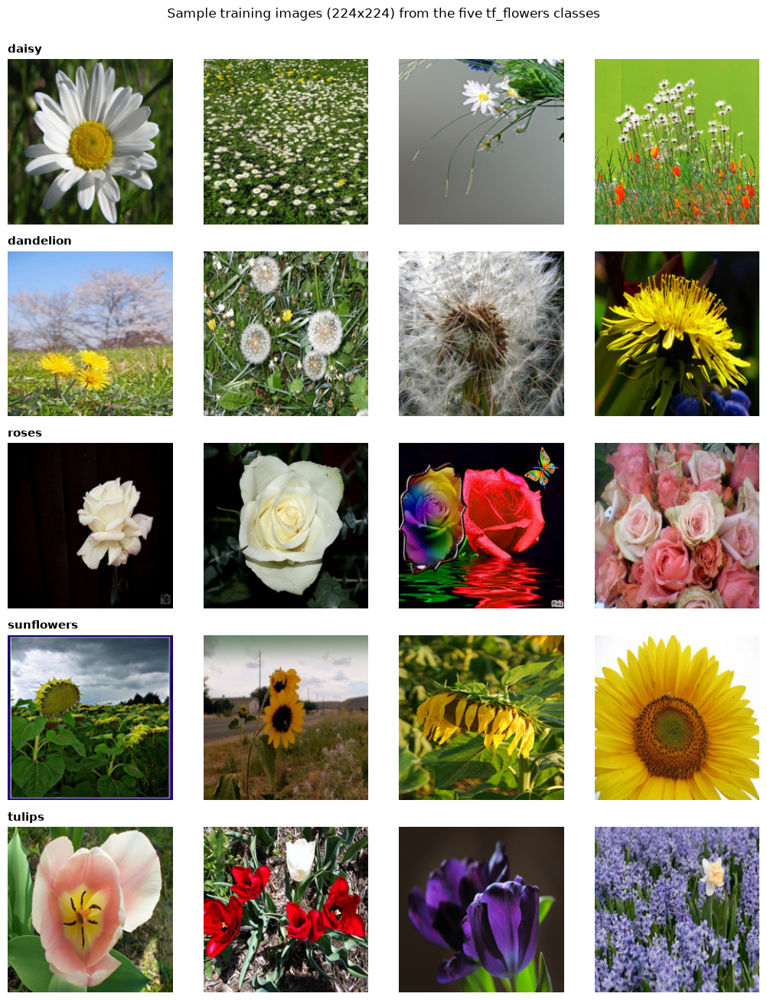

In [4]:
# ============================ FIGURE: sample input images from all five classes (spec §31-1) ============================
def show_save(fig, fname):
    fig.savefig(os.path.join(FIG_DIR, fname), dpi=200, bbox_inches="tight"); plt.show()

per_class = 4
fig, axes = plt.subplots(NUM_CLASSES, per_class, figsize=(2.6 * per_class, 2.6 * NUM_CLASSES), squeeze=False)
rs = np.random.default_rng(SEED)
for c in range(NUM_CLASSES):
    pool = np.where(y_train == c)[0]
    sel = rs.choice(pool, min(per_class, len(pool)), replace=False)
    for j in range(per_class):
        ax = axes[c, j]; ax.axis("off")
        if j < len(sel): ax.imshow(X_train[sel[j]])
        if j == 0: ax.set_title(CLASS_NAMES[c], loc="left", fontsize=11, fontweight="bold")
fig.suptitle("Sample training images (224x224) from the five tf_flowers classes", y=1.0)
fig.tight_layout(); show_save(fig, "fig01_sample_images.png")

In [5]:
# ============================ INPUT PIPELINE: preprocessing + augmentation (spec §3.1) ============================
preprocess = keras.applications.resnet50.preprocess_input        # the ImageNet preprocessing expected by ResNet50

def build_augmentation():
    # the SAME augmentation strategy and seeds are used for every model
    return keras.Sequential([
        layers.RandomFlip("horizontal", seed=SEED),
        layers.RandomRotation(0.05, seed=SEED),                  # about +-18 degrees
        layers.RandomZoom(0.10, seed=SEED),
        layers.RandomTranslation(0.10, 0.10, seed=SEED),
        layers.RandomContrast(0.10, seed=SEED),
    ], name="augmentation")

def make_train_ds(X, Y):
    aug = build_augmentation()                                   # fresh object -> identical random stream for every model
    ds = tf.data.Dataset.from_tensor_slices((X, Y)).shuffle(len(X), seed=SEED, reshuffle_each_iteration=True).batch(BATCH_SIZE)
    ds = ds.map(lambda a, b: (preprocess(aug(tf.cast(a, tf.float32), training=True)), b), num_parallel_calls=1, deterministic=True)
    return ds.prefetch(tf.data.AUTOTUNE)

def make_eval_ds(X, Y):
    ds = tf.data.Dataset.from_tensor_slices((X, Y)).batch(BATCH_SIZE)
    return ds.map(lambda a, b: (preprocess(tf.cast(a, tf.float32)), b)).prefetch(tf.data.AUTOTUNE)

def pp(x): return preprocess(np.asarray(x, dtype="float32").copy())    # numpy uint8 -> ResNet50-preprocessed float32
print("pipeline ready: train batches/epoch =", math.ceil(len(X_train) / BATCH_SIZE))

pipeline ready: train batches/epoch = 81


## 1. Attention modules and ResNet50 with attention inserted at P1 … P4 (spec §7, §9–§13, §19)
`build_model()` re-assembles the *pretrained* ResNet50 stage by stage (re-using the original layer objects, so the ImageNet weights are untouched) and splices an attention block after the chosen stage(s):

`conv2_x → [P1] → conv3_x → [P2] → conv4_x → [P3] → conv5_x → [P4] → GAP → Dropout → Dense(5)`

All attention blocks preserve `H×W×C`; a sanity cell below verifies this for every module and position.

In [6]:
# ============================ ATTENTION MODULES ============================
class ChannelAttention(layers.Layer):
    """M_c(F) = sigmoid(W2 relu(W1 GAP(F)));  F_c = F * M_c(F)   (== Squeeze-and-Excitation block)"""
    def __init__(self, reduction=16, **kw):
        super().__init__(**kw); self.reduction = reduction
    def build(self, input_shape):
        c = int(input_shape[-1])
        self.fc1 = layers.Dense(max(c // self.reduction, 4), activation="relu")
        self.fc2 = layers.Dense(c, activation="sigmoid")
        super().build(input_shape)
    def attention_map(self, x):
        z = tf.reduce_mean(x, axis=[1, 2])
        return tf.reshape(self.fc2(self.fc1(z)), [-1, 1, 1, x.shape[-1]])
    def call(self, x): return x * self.attention_map(x)

class SpatialAttention(layers.Layer):
    """M_s(F) = sigmoid(Conv_kxk([mean_c(F) || max_c(F)]));  F_s = F * M_s(F)"""
    def __init__(self, kernel_size=7, **kw):
        super().__init__(**kw); self.kernel_size = kernel_size
    def build(self, input_shape):
        self.conv = layers.Conv2D(1, self.kernel_size, padding="same", activation="sigmoid")
        super().build(input_shape)
    def attention_map(self, x):
        f_avg = tf.reduce_mean(x, axis=-1, keepdims=True); f_max = tf.reduce_max(x, axis=-1, keepdims=True)
        return self.conv(tf.concat([f_avg, f_max], axis=-1))
    def call(self, x): return x * self.attention_map(x)

class SelfAttention(layers.Layer):
    """Lightweight non-local self-attention. Q=XW_Q, K=XW_K, V=XW_V, A=softmax(QK^T/sqrt(d)), Y=AV,
    F_SA = F + gamma*reshape(Y W_O).  d=C/8 for Q,K ; C/2 for V ; gamma is learnable and initialised to 0."""
    def __init__(self, qk_div=8, v_div=2, **kw):
        super().__init__(**kw); self.qk_div, self.v_div = qk_div, v_div
    def build(self, input_shape):
        c = int(input_shape[-1])
        self.dqk, self.dv = max(c // self.qk_div, 8), max(c // self.v_div, 8)
        self.wq = layers.Dense(self.dqk, use_bias=False); self.wk = layers.Dense(self.dqk, use_bias=False)
        self.wv = layers.Dense(self.dv, use_bias=False);  self.wo = layers.Dense(c, use_bias=False)
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)
        super().build(input_shape)
    def attention_matrix(self, x):                                  # (B, N, N), rows sum to 1
        b = tf.shape(x)[0]; n = x.shape[1] * x.shape[2]
        xf = tf.reshape(x, [b, n, x.shape[-1]]); q, k = self.wq(xf), self.wk(xf)
        return tf.nn.softmax(tf.matmul(q, k, transpose_b=True) / tf.sqrt(tf.cast(self.dqk, x.dtype)), axis=-1)
    def response(self, x):                                          # gamma * reshape(Y W_O): what is added to F
        b = tf.shape(x)[0]; h, w, c = x.shape[1], x.shape[2], x.shape[3]
        xf = tf.reshape(x, [b, h * w, c]); a = self.attention_matrix(x)
        return self.gamma * tf.reshape(self.wo(tf.matmul(a, self.wv(xf))), [b, h, w, c])
    def call(self, x): return x + self.response(x)

class ECA(layers.Layer):
    """Efficient Channel Attention: GAP -> 1-D conv across channels (adaptive kernel size) -> sigmoid."""
    def __init__(self, gamma=2, b=1, **kw):
        super().__init__(**kw); self.g, self.b = gamma, b
    def build(self, input_shape):
        c = int(input_shape[-1]); k = int(abs((np.log2(c) + self.b) / self.g)); self.k = k if k % 2 else k + 1
        self.conv = layers.Conv1D(1, self.k, padding="same", use_bias=False, activation="sigmoid")
        super().build(input_shape)
    def attention_map(self, x):
        z = tf.reduce_mean(x, axis=[1, 2]); m = self.conv(tf.expand_dims(z, -1))
        return tf.reshape(m, [-1, 1, 1, x.shape[-1]])
    def call(self, x): return x * self.attention_map(x)

class CBAMChannel(layers.Layer):
    """CBAM channel gate: sigmoid(MLP(GAP(F)) + MLP(GMP(F))) with a shared MLP."""
    def __init__(self, reduction=16, **kw):
        super().__init__(**kw); self.reduction = reduction
    def build(self, input_shape):
        c = int(input_shape[-1])
        self.fc1 = layers.Dense(max(c // self.reduction, 4), activation="relu"); self.fc2 = layers.Dense(c)
        super().build(input_shape)
    def attention_map(self, x):
        a = self.fc2(self.fc1(tf.reduce_mean(x, axis=[1, 2]))); m = self.fc2(self.fc1(tf.reduce_max(x, axis=[1, 2])))
        return tf.reshape(tf.nn.sigmoid(a + m), [-1, 1, 1, x.shape[-1]])
    def call(self, x): return x * self.attention_map(x)

class CoordinateAttention(layers.Layer):
    """Coordinate Attention (Hou et al., 2021): direction-aware pooling along H and along W."""
    def __init__(self, reduction=32, **kw):
        super().__init__(**kw); self.reduction = reduction
    def build(self, input_shape):
        c = int(input_shape[-1]); mip = max(8, c // self.reduction)
        self.conv1 = layers.Conv2D(mip, 1); self.bn = layers.BatchNormalization()
        self.conv_h = layers.Conv2D(c, 1, activation="sigmoid"); self.conv_w = layers.Conv2D(c, 1, activation="sigmoid")
        super().build(input_shape)
    def attention_maps(self, x, training=False):
        h, w = x.shape[1], x.shape[2]
        x_h = tf.reduce_mean(x, axis=2, keepdims=True)
        x_w = tf.transpose(tf.reduce_mean(x, axis=1, keepdims=True), [0, 2, 1, 3])
        y = self.bn(self.conv1(tf.concat([x_h, x_w], axis=1)), training=training)
        y = y * tf.nn.relu6(y + 3.0) / 6.0                                        # h-swish
        y_h, y_w = tf.split(y, [h, w], axis=1)
        return self.conv_h(y_h), tf.transpose(self.conv_w(y_w), [0, 2, 1, 3])      # (B,H,1,C), (B,1,W,C)
    def call(self, x, training=False):
        a_h, a_w = self.attention_maps(x, training=training); return x * a_h * a_w

class AttentionBlock(layers.Layer):
    """kind: channel | spatial | cs (C->S) | sc (S->C) | self | combined (C->S->Self) | eca | cbam | coord"""
    def __init__(self, kind, kernel_size=7, reduction=16, **kw):
        super().__init__(**kw)
        self.kind, self.kernel_size, self.reduction = kind, kernel_size, reduction
        k = kind
        self.ch = ChannelAttention(reduction, name="ch") if k in ("channel", "cs", "sc", "combined") else None
        self.sp = SpatialAttention(kernel_size, name="sp") if k in ("spatial", "cs", "sc", "combined") else None
        self.sa = SelfAttention(name="sa") if k in ("self", "combined") else None
        self.eca = ECA(name="eca") if k == "eca" else None
        self.cbam_c = CBAMChannel(reduction, name="cbam_c") if k == "cbam" else None
        self.cbam_s = SpatialAttention(7, name="cbam_s") if k == "cbam" else None
        self.coord = CoordinateAttention(name="coord") if k == "coord" else None
    def call(self, x, training=False):
        k = self.kind
        if k == "channel":  return self.ch(x)
        if k == "spatial":  return self.sp(x)
        if k == "cs":       return self.sp(self.ch(x))            # channel -> spatial
        if k == "sc":       return self.ch(self.sp(x))            # spatial -> channel
        if k == "self":     return self.sa(x)
        if k == "combined": return self.sa(self.sp(self.ch(x)))   # channel -> spatial -> self-attention
        if k == "eca":      return self.eca(x)
        if k == "cbam":     return self.cbam_s(self.cbam_c(x))
        if k == "coord":    return self.coord(x, training=training)
        raise ValueError(k)
    def internal_maps(self, x):
        """Internal attention tensors computed in the forward pass, given the incoming feature tensor x."""
        out, k, xc = {}, self.kind, x
        if k in ("channel", "cs", "combined"):
            out["channel"] = self.ch.attention_map(x); xc = x * out["channel"]
        if k == "spatial": out["spatial"] = self.sp.attention_map(x)
        if k in ("cs", "combined"):
            out["spatial"] = self.sp.attention_map(xc); xc = xc * out["spatial"]
        if k == "sc":
            out["spatial"] = self.sp.attention_map(x); out["channel"] = self.ch.attention_map(x * out["spatial"])
        if k in ("self", "combined"):
            out["self"] = self.sa.attention_matrix(xc); out["self_input"] = xc
        if k == "eca":  out["channel"] = self.eca.attention_map(x)
        if k == "cbam":
            out["channel"] = self.cbam_c.attention_map(x); out["spatial"] = self.cbam_s.attention_map(x * out["channel"])
        if k == "coord": out["coord_h"], out["coord_w"] = self.coord.attention_maps(x, training=False)
        return out

# ============================ RESNET50 WITH ATTENTION SPLICED IN ============================
STAGES = {1: ("conv2", 3), 2: ("conv3", 4), 3: ("conv4", 6), 4: ("conv5", 3)}      # P_k -> (stage name, #bottleneck blocks)

def _bottleneck(base, x, stage, block):
    pre = f"{stage}_block{block}"; sc = x
    if block == 1:
        sc = base.get_layer(f"{pre}_0_bn")(base.get_layer(f"{pre}_0_conv")(x))
    y = x
    for i in (1, 2):
        y = base.get_layer(f"{pre}_{i}_relu")(base.get_layer(f"{pre}_{i}_bn")(base.get_layer(f"{pre}_{i}_conv")(y)))
    y = base.get_layer(f"{pre}_3_bn")(base.get_layer(f"{pre}_3_conv")(y))
    return base.get_layer(f"{pre}_out")(base.get_layer(f"{pre}_add")([sc, y]))

def build_model(attention=None, weights="imagenet", num_classes=NUM_CLASSES, dropout=DROPOUT):
    """attention: {position(1..4): dict(kind=..., kernel_size=7)}; None/{} -> baseline pretrained ResNet50."""
    attention = attention or {}
    base = keras.applications.ResNet50(include_top=False, weights=weights, input_shape=(IMG_SIZE, IMG_SIZE, 3))
    x = base.input
    for name in ["conv1_pad", "conv1_conv", "conv1_bn", "conv1_relu", "pool1_pad", "pool1_pool"]:
        x = base.get_layer(name)(x)
    taps = {}
    for p in (1, 2, 3, 4):
        stage, nblocks = STAGES[p]
        for b in range(1, nblocks + 1): x = _bottleneck(base, x, stage, b)
        taps[f"P{p}_stage_out"] = x
        if p in attention:
            cfg = attention[p]; taps[f"P{p}_pre"] = x
            x = AttentionBlock(cfg["kind"], cfg.get("kernel_size", 7), REDUCTION, name=f"att_P{p}")(x)
            taps[f"P{p}_post"] = x
    x = layers.Activation("linear", name="final_features")(x)      # last feature map (input of GAP) -> used by Grad-CAM
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(dropout, name="drop")(x)
    logits = layers.Dense(num_classes, name="logits")(x)
    probs = layers.Activation("softmax", name="probs")(logits)
    return keras.Model(base.input, probs, name="resnet50_att"), taps
print("attention modules defined")

attention modules defined


In [7]:
# ============================ SANITY CHECKS BEFORE ANY TRAINING ============================
# (1) rebuilt baseline must be numerically identical to the stock Keras ResNet50
_stock = keras.applications.ResNet50(include_top=False, weights=WEIGHTS, input_shape=(IMG_SIZE, IMG_SIZE, 3))
_rebuilt, _ = build_model({}, weights=WEIGHTS)
for _l in _stock.layers:                                   # copy stock weights layer-by-layer -> tests the re-wiring itself, in any mode
    if _l.weights: _rebuilt.get_layer(_l.name).set_weights(_l.get_weights())
_xb = pp(X_train[:4])
_a = _stock(_xb, training=False).numpy()
_b = keras.Model(_rebuilt.input, _rebuilt.get_layer("final_features").output)(_xb, training=False).numpy()
print(f"[check 1] rebuilt-baseline vs stock ResNet50 feature map: max |diff| = {np.abs(_a - _b).max():.2e}  (must be ~0)")
assert np.abs(_a - _b).max() < 1e-3
del _stock, _rebuilt

# (2) every module at every position keeps H x W x C  (spec §13: record dimensions before / after attention)
_rows = []
for kind in ["channel", "spatial", "cs", "sc", "self", "combined", "eca", "cbam", "coord"]:
    for p in (1, 2, 3, 4):
        if kind in ("self", "combined") and p == 1: continue      # N=3136 -> 3136x3136 matrix: skipped on purpose (spec §12)
        _m, _t = build_model({p: dict(kind=kind)}, weights=None)
        pre, post = tuple(_t[f"P{p}_pre"].shape[1:]), tuple(_t[f"P{p}_post"].shape[1:])
        assert pre == post, (kind, p, pre, post)
        n = sum(int(np.prod(w.shape)) for l in _m.layers if l.name.startswith("att_") for w in l.weights)
        _rows.append(dict(module=kind, position=f"P{p}", before=str(pre), after=str(post), module_params=n))
        del _m; keras.backend.clear_session(); gc.collect()
DIMS_CHECK = pd.DataFrame(_rows)
DIMS_CHECK.to_csv(os.path.join(TAB_DIR, "attention_module_dimensions_all_positions.csv"), index=False)
print("[check 2] all modules preserve the feature-tensor shape. Module sizes / dimensions:")
display(DIMS_CHECK)
keras.backend.clear_session(); gc.collect()

       0/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step

   16384/94765736 ━━━━━━━━━━━━━━━━━━━━ 16:17 10us/step

   32768/94765736 ━━━━━━━━━━━━━━━━━━━━ 11:23 7us/step 

   49152/94765736 ━━━━━━━━━━━━━━━━━━━━ 12:44 8us/step

   81920/94765736 ━━━━━━━━━━━━━━━━━━━━ 11:57 8us/step

  114688/94765736 ━━━━━━━━━━━━━━━━━━━━ 9:35 6us/step 

... (191 outputs left out)

[check 1] rebuilt-baseline vs stock ResNet50 feature map: max |diff| = 0.00e+00  (must be ~0)


[check 2] all modules preserve the feature-tensor shape. Module sizes / dimensions:


,module,position,before,after,module_params
0,channel,P1,"(56, 56, 256)","(56, 56, 256)",8464
1,channel,P2,"(28, 28, 512)","(28, 28, 512)",33312
2,channel,P3,"(14, 14, 1024)","(14, 14, 1024)",132160
3,channel,P4,"(7, 7, 2048)","(7, 7, 2048)",526464
4,spatial,P1,"(56, 56, 256)","(56, 56, 256)",99
5,spatial,P2,"(28, 28, 512)","(28, 28, 512)",99
6,spatial,P3,"(14, 14, 1024)","(14, 14, 1024)",99
7,spatial,P4,"(7, 7, 2048)","(7, 7, 2048)",99
8,cs,P1,"(56, 56, 256)","(56, 56, 256)",8563
9,cs,P2,"(28, 28, 512)","(28, 28, 512)",33411


0

## 2. Experiment registry, training protocol and evaluation utilities (spec §20–§22, §34)
Every model uses the **same** protocol (see the configuration cell). Training is two-phase transfer learning exactly as in §20: (1) backbone frozen, train attention + classifier at LR `1e-3`; (2) unfreeze the final ResNet50 stage `conv5_x` (BatchNorm layers stay frozen) and fine-tune at LR `1e-4` with cosine decay. The weights of the epoch with the best **validation** accuracy are restored (test data are never used for any selection).

In [8]:
# ============================ EXPERIMENT REGISTRY ============================
EXPERIMENTS = {}
def add(name, label, short, group, pos, att): EXPERIMENTS[name] = dict(label=label, short=short, group=group, pos=pos, att=att)
cs = lambda k=7: dict(kind="cs", kernel_size=k)
# --- Main Experiment 1 : attention type @ P3 (spec §14)
add("A0_Baseline",    "Baseline ResNet50",              "Baseline",    "Exp1", "--", {})
add("A1_Channel_P3",  "Channel Attention (SE)",         "Channel/SE",  "Exp1", "P3", {3: dict(kind="channel")})
add("A2_Spatial_P3",  "Spatial Attention (k=7)",        "Spatial",     "Exp1", "P3", {3: dict(kind="spatial", kernel_size=7)})
add("A3_CS_P3",       "Channel+Spatial (C->S, k=7)",    "C+S",         "Exp1", "P3", {3: cs(7)})
add("A4_Self_P3",     "Self-Attention",                 "Self-Attn",   "Exp1", "P3", {3: dict(kind="self")})
add("A5_Combined_P3", "Combined (C->S->Self)",          "Combined",    "Exp1", "P3", {3: dict(kind="combined", kernel_size=7)})
# --- Main Experiment 2 : attention position, C->S (spec §15);  B3 == A3
add("B1_CS_P1",       "Channel+Spatial @ P1",           "C+S @P1",     "Exp2", "P1", {1: cs(7)})
add("B2_CS_P2",       "Channel+Spatial @ P2",           "C+S @P2",     "Exp2", "P2", {2: cs(7)})
add("B4_CS_P4",       "Channel+Spatial @ P4",           "C+S @P4",     "Exp2", "P4", {4: cs(7)})
# --- Main Experiment 3 : multiple positions (spec §16)
add("M34_CS_P3P4",    "Channel+Spatial @ P3+P4",        "C+S @P3+P4",  "Exp3", "P3+P4", {3: cs(7), 4: cs(7)})
if RUN_EXTENDED:
    add("M234_CS_P2P3P4", "Channel+Spatial @ P2+P3+P4", "C+S @P2+P3+P4", "Exp3", "P2+P3+P4", {2: cs(7), 3: cs(7), 4: cs(7)})
# --- Main Experiment 4 : attention order (spec §17)
add("O1_SC_P3",       "Spatial->Channel @ P3",          "S->C @P3",    "Exp4", "P3", {3: dict(kind="sc", kernel_size=7)})
# --- Main Experiment 5 : spatial kernel size, C->S @ P3 (spec §18); k=7 == A3
add("K3_CS_P3",       "Channel+Spatial, k=3",           "C+S k=3",     "Exp5", "P3", {3: cs(3)})
add("K5_CS_P3",       "Channel+Spatial, k=5",           "C+S k=5",     "Exp5", "P3", {3: cs(5)})
# --- Additional mechanisms @ P3 (spec §19, §36)
add("X1_ECA_P3",      "ECA",                            "ECA",         "Extra", "P3", {3: dict(kind="eca")})
add("X2_CBAM_P3",     "CBAM",                           "CBAM",        "Extra", "P3", {3: dict(kind="cbam")})
add("X3_Coord_P3",    "Coordinate Attention",           "CoordAtt",    "Extra", "P3", {3: dict(kind="coord")})

GROUPS = {"Exp1": ["A0_Baseline", "A1_Channel_P3", "A2_Spatial_P3", "A3_CS_P3", "A4_Self_P3", "A5_Combined_P3"],
          "Exp2": ["B1_CS_P1", "B2_CS_P2", "B4_CS_P4"],
          "Exp3": [n for n in ["M34_CS_P3P4", "M234_CS_P2P3P4"] if n in EXPERIMENTS],
          "Exp4": ["O1_SC_P3"], "Exp5": ["K3_CS_P3", "K5_CS_P3"], "Extra": ["X1_ECA_P3", "X2_CBAM_P3", "X3_Coord_P3"]}
_pal = plt.get_cmap("tab20")
COLORS = {n: _pal(i % 20) for i, n in enumerate(EXPERIMENTS)}
print(f"{len(EXPERIMENTS)} models registered:"); display(pd.DataFrame([{"name": n, **{k: v for k, v in e.items() if k != 'att'}, "att": str(e['att'])} for n, e in EXPERIMENTS.items()]))

17 models registered:


,name,label,short,group,pos,att
0,A0_Baseline,Baseline ResNet50,Baseline,Exp1,--,{}
1,A1_Channel_P3,Channel Attention (SE),Channel/SE,Exp1,P3,{3: {'kind': 'channel'}}
2,A2_Spatial_P3,Spatial Attention (k=7),Spatial,Exp1,P3,"{3: {'kind': 'spatial', 'kernel_size': 7}}"
3,A3_CS_P3,"Channel+Spatial (C->S, k=7)",C+S,Exp1,P3,"{3: {'kind': 'cs', 'kernel_size': 7}}"
4,A4_Self_P3,Self-Attention,Self-Attn,Exp1,P3,{3: {'kind': 'self'}}
5,A5_Combined_P3,Combined (C->S->Self),Combined,Exp1,P3,"{3: {'kind': 'combined', 'kernel_size': 7}}"
6,B1_CS_P1,Channel+Spatial @ P1,C+S @P1,Exp2,P1,"{1: {'kind': 'cs', 'kernel_size': 7}}"
7,B2_CS_P2,Channel+Spatial @ P2,C+S @P2,Exp2,P2,"{2: {'kind': 'cs', 'kernel_size': 7}}"
8,B4_CS_P4,Channel+Spatial @ P4,C+S @P4,Exp2,P4,"{4: {'kind': 'cs', 'kernel_size': 7}}"
9,M34_CS_P3P4,Channel+Spatial @ P3+P4,C+S @P3+P4,Exp3,P3+P4,"{3: {'kind': 'cs', 'kernel_size': 7}, 4: {'kind': 'cs', ..."


In [9]:
# ============================ TRAINING / EVALUATION UTILITIES ============================
def paths(name):
    return dict(w=os.path.join(W_DIR, f"{name}.weights.h5"), r=os.path.join(RES_DIR, f"{name}.json"), p=os.path.join(PRED_DIR, f"{name}_test_probs.npy"))

def is_done(name):
    P = paths(name)
    if not (os.path.exists(P["r"]) and os.path.exists(P["w"]) and os.path.exists(P["p"])): return False
    return json.load(open(P["r"])).get("config_sig") == CONFIG_SIG

def n_params(model):
    tr = int(sum(np.prod(w.shape) for w in model.trainable_weights)); return model.count_params(), tr

def att_param_count(model):
    return int(sum(np.prod(w.shape) for l in model.layers if l.name.startswith("att_") for w in l.weights))

def set_trainable(model, phase):
    for l in model.layers:
        if l.name.startswith("att_") or l.name == "logits": l.trainable = True            # new layers: always trained
        elif phase == 2 and l.name.startswith(UNFREEZE_PREFIXES) and not isinstance(l, layers.BatchNormalization): l.trainable = True
        else: l.trainable = False                                                           # pretrained & frozen (BN stays frozen)

def predict_probs(model, X, bs=BATCH_SIZE):
    return np.concatenate([model(pp(X[i:i + bs]), training=False).numpy() for i in range(0, len(X), bs)])

def ce_loss(y, probs): return float(-np.mean(np.log(np.clip(probs[np.arange(len(y)), y], 1e-7, 1.0))))

def compute_metrics(y, probs):
    pred = probs.argmax(1)
    p, r, f, _ = precision_recall_fscore_support(y, pred, average="macro", zero_division=0)
    pc, rc, fc, sc = precision_recall_fscore_support(y, pred, labels=list(range(NUM_CLASSES)), zero_division=0)
    return dict(accuracy=float((pred == y).mean()), precision=float(p), recall=float(r), f1=float(f), loss=ce_loss(y, probs),
                per_class=dict(precision=pc.tolist(), recall=rc.tolist(), f1=fc.tolist(), support=sc.tolist()),
                confusion=confusion_matrix(y, pred, labels=list(range(NUM_CLASSES))).tolist())

def time_inference(model, X, reps=5, bs=BATCH_SIZE):
    """Average inference time per image (ms): batched (bs=32) median of `reps` passes, plus batch-size-1 latency."""
    f = tf.function(lambda x: model(x, training=False), input_signature=[tf.TensorSpec([None, IMG_SIZE, IMG_SIZE, 3], tf.float32)])
    xs = [tf.constant(pp(X[i:i + bs])) for i in range(0, len(X), bs)]
    for x in (xs[0], xs[-1]): f(x).numpy()                                                  # warm-up / tracing
    t_b = []
    for _ in range(reps):
        t = time.perf_counter()
        for x in xs: f(x).numpy()
        t_b.append((time.perf_counter() - t) / len(X) * 1000)
    ones = [tf.constant(pp(X[i:i + 1])) for i in range(min(100, len(X)))]
    f(ones[0]).numpy(); t = time.perf_counter()
    for x in ones: f(x).numpy()
    return float(np.median(t_b)), float((time.perf_counter() - t) / len(ones) * 1000)

class BestTracker(keras.callbacks.Callback):
    """Keeps the weights of the best validation epoch over BOTH training phases (key: val_acc, then val_loss)."""
    def __init__(self): super().__init__(); self.key, self.weights, self.epoch, self.n = None, None, -1, 0
    def on_epoch_end(self, epoch, logs=None):
        k = (round(logs["val_accuracy"], 6), -logs["val_loss"])
        if self.key is None or k > self.key: self.key, self.weights, self.epoch = k, self.model.get_weights(), self.n
        self.n += 1

def train_one(name):
    cfg = EXPERIMENTS[name]; P = paths(name); t0 = time.time()
    keras.backend.clear_session(); keras.utils.set_random_seed(SEED)
    model, taps = build_model(cfg["att"], weights=WEIGHTS)
    dims = {f"P{p}": dict(before=list(taps[f"P{p}_pre"].shape[1:]), after=list(taps[f"P{p}_post"].shape[1:])) for p in cfg["att"]}
    tr, va = make_train_ds(X_train, Y_train), make_eval_ds(X_val, Y_val)
    spe = math.ceil(len(X_train) / BATCH_SIZE); tracker = BestTracker(); hist = {}
    def merge(h):
        for k, v in h.history.items(): hist.setdefault(k, []).extend([float(a) for a in v])
    print(f"\n=== {name} | {cfg['label']} | att={cfg['att']} ===")
    set_trainable(model, 1); tot, trn1 = n_params(model)
    model.compile(keras.optimizers.Adam(LR_HEAD), loss="categorical_crossentropy", metrics=["accuracy"])
    merge(model.fit(tr, validation_data=va, epochs=EPOCHS_FROZEN, callbacks=[tracker], verbose=2))
    set_trainable(model, 2); _, trn2 = n_params(model)
    sched = keras.optimizers.schedules.CosineDecay(LR_FINETUNE, EPOCHS_FINETUNE * spe)
    model.compile(keras.optimizers.Adam(sched), loss="categorical_crossentropy", metrics=["accuracy"])
    merge(model.fit(tr, validation_data=va, epochs=EPOCHS_FINETUNE, callbacks=[tracker], verbose=2))
    model.set_weights(tracker.weights)                                                       # restore best-validation epoch
    pr_tr, pr_va, pr_te = (predict_probs(model, X) for X in (X_train, X_val, X_test))
    m_tr, m_va, m_te = compute_metrics(y_train, pr_tr), compute_metrics(y_val, pr_va), compute_metrics(y_test, pr_te)
    ms_b, ms_1 = time_inference(model, X_test)
    gam = {l.name: float(l.sa.gamma.numpy()) for l in model.layers if l.name.startswith("att_") and getattr(l, "sa", None) is not None}
    res = dict(name=name, label=cfg["label"], short=cfg["short"], group=cfg["group"], pos=cfg["pos"],
               att={str(k): v for k, v in cfg["att"].items()}, dims=dims, history=hist, phase1_epochs=EPOCHS_FROZEN,
               best_epoch=int(tracker.epoch) + 1, train=m_tr, val=m_va, test=m_te,
               params_total=tot, params_trainable_phase1=trn1, params_trainable_phase2=trn2, params_attention=att_param_count(model),
               inference_ms_bs32=ms_b, latency_ms_bs1=ms_1, gamma=gam, train_seconds=time.time() - t0, config_sig=CONFIG_SIG)
    model.save_weights(P["w"]); np.save(P["p"], pr_te); json.dump(res, open(P["r"], "w"))
    print(f"[{name}] best epoch {res['best_epoch']} | test acc {m_te['accuracy']:.4f}  macro-F1 {m_te['f1']:.4f} | params {tot:,} (att {res['params_attention']:,}) | {ms_b:.2f} ms/img | {res['train_seconds']/60:.1f} min")
    del model, taps; keras.backend.clear_session(); gc.collect()

def run_group(names):
    for n in names:
        if is_done(n) and not FORCE_RETRAIN: print(f"[skip] {n}: already trained (results found in {RES_DIR})"); continue
        train_one(n)
    rows = []
    for n in names:
        r = json.load(open(paths(n)["r"])); t = r["test"]
        rows.append(dict(model=n, acc=t["accuracy"], precision=t["precision"], recall=t["recall"], f1=t["f1"], best_epoch=r["best_epoch"],
                         params=r["params_total"], ms_per_img=r["inference_ms_bs32"]))
    display(pd.DataFrame(rows).round(4))
print("utilities ready")

utilities ready


### 2.1 Training — Main Experiment 1: attention-type ablation @ P3 (spec §14)
`A0` baseline · `A1` channel · `A2` spatial · `A3` channel→spatial · `A4` self-attention · `A5` combined (C→S→Self). Only the attention type changes.

In [10]:
run_group(GROUPS["Exp1"])


=== A0_Baseline | Baseline ResNet50 | att={} ===
Epoch 1/5


81/81 - 83s - 1s/step - accuracy: 0.6789 - loss: 0.8868 - val_accuracy: 0.8748 - val_loss: 0.3487


Epoch 2/5


81/81 - 51s - 628ms/step - accuracy: 0.8509 - loss: 0.4317 - val_accuracy: 0.9111 - val_loss: 0.2808


Epoch 3/5


81/81 - 51s - 630ms/step - accuracy: 0.8653 - loss: 0.3609 - val_accuracy: 0.9020 - val_loss: 0.2844


... (177 outputs left out)

Epoch 10/10


81/81 - 51s - 626ms/step - accuracy: 0.9926 - loss: 0.0178 - val_accuracy: 0.9328 - val_loss: 0.3170


[A5_Combined_P3] best epoch 5 | test acc 0.9127  macro-F1 0.9119 | params 25,040,937 (att 1,442,980) | 1.33 ms/img | 14.5 min


,model,acc,precision,recall,f1,best_epoch,params,ms_per_img
0,A0_Baseline,0.9455,0.9477,0.9447,0.9459,14,23597957,1.1815
1,A1_Channel_P3,0.9527,0.9512,0.9524,0.9517,12,23730117,1.2146
2,A2_Spatial_P3,0.9436,0.9447,0.9430,0.9435,10,23598056,1.2148
3,A3_CS_P3,0.9436,0.9466,0.9413,0.9435,12,23730216,1.2213
4,A4_Self_P3,0.9345,0.9346,0.9340,0.9342,13,24908678,1.2671
5,A5_Combined_P3,0.9127,0.9107,0.9143,0.9119,5,25040937,1.3317


### 2.2 Training — Main Experiment 2: attention-position ablation (spec §15)
Same channel→spatial module at P1 (`B1`), P2 (`B2`), P3 (`B3` ≡ `A3`, trained above), P4 (`B4`). Only the position changes.

In [11]:
run_group(GROUPS["Exp2"])


=== B1_CS_P1 | Channel+Spatial @ P1 | att={1: {'kind': 'cs', 'kernel_size': 7}} ===
Epoch 1/5


81/81 - 83s - 1s/step - accuracy: 0.3367 - loss: 1.6570 - val_accuracy: 0.6388 - val_loss: 0.9516


Epoch 2/5


81/81 - 51s - 625ms/step - accuracy: 0.6816 - loss: 0.8169 - val_accuracy: 0.8058 - val_loss: 0.5602


Epoch 3/5


81/81 - 51s - 624ms/step - accuracy: 0.8038 - loss: 0.5415 - val_accuracy: 0.8548 - val_loss: 0.4271


... (84 outputs left out)

Epoch 10/10


81/81 - 51s - 628ms/step - accuracy: 0.9996 - loss: 0.0037 - val_accuracy: 0.9383 - val_loss: 0.2938


[B4_CS_P4] best epoch 13 | test acc 0.9455  macro-F1 0.9447 | params 24,124,520 (att 526,563) | 1.22 ms/img | 14.2 min


,model,acc,precision,recall,f1,best_epoch,params,ms_per_img
0,B1_CS_P1,0.9291,0.9322,0.9283,0.9292,11,23606520,1.2602
1,B2_CS_P2,0.9473,0.9504,0.9457,0.9470,12,23631368,1.2355
2,B4_CS_P4,0.9455,0.9455,0.9443,0.9447,13,24124520,1.2165


### 2.3 Training — Main Experiment 3: multiple attention positions (spec §16)
Single positions are `A3` (P3 only) and `B4` (P4 only); here `M34` = P3+P4 and the extended `M234` = P2+P3+P4.

In [12]:
run_group(GROUPS["Exp3"])


=== M34_CS_P3P4 | Channel+Spatial @ P3+P4 | att={3: {'kind': 'cs', 'kernel_size': 7}, 4: {'kind': 'cs', 'kernel_size': 7}} ===
Epoch 1/5


81/81 - 77s - 945ms/step - accuracy: 0.4632 - loss: 1.2207 - val_accuracy: 0.8348 - val_loss: 0.4276


Epoch 2/5


81/81 - 51s - 626ms/step - accuracy: 0.8494 - loss: 0.3966 - val_accuracy: 0.8929 - val_loss: 0.2981


Epoch 3/5


81/81 - 50s - 622ms/step - accuracy: 0.9054 - loss: 0.2590 - val_accuracy: 0.9129 - val_loss: 0.3062


... (53 outputs left out)

Epoch 10/10


81/81 - 50s - 622ms/step - accuracy: 0.9969 - loss: 0.0093 - val_accuracy: 0.9274 - val_loss: 0.3701


[M234_CS_P2P3P4] best epoch 12 | test acc 0.9364  macro-F1 0.9364 | params 24,290,190 (att 692,233) | 1.25 ms/img | 14.3 min


,model,acc,precision,recall,f1,best_epoch,params,ms_per_img
0,M34_CS_P3P4,0.9436,0.9429,0.9433,0.9429,13,24256779,1.2277
1,M234_CS_P2P3P4,0.9364,0.9367,0.9366,0.9364,12,24290190,1.2550


### 2.4 Training — Main Experiment 4: attention order (spec §17)
Channel→Spatial is `A3`; Spatial→Channel (`O1`) is trained here at the same position (P3).

In [13]:
run_group(GROUPS["Exp4"])


=== O1_SC_P3 | Spatial->Channel @ P3 | att={3: {'kind': 'sc', 'kernel_size': 7}} ===
Epoch 1/5


81/81 - 74s - 910ms/step - accuracy: 0.6641 - loss: 0.8594 - val_accuracy: 0.9038 - val_loss: 0.3041


Epoch 2/5


81/81 - 51s - 626ms/step - accuracy: 0.8599 - loss: 0.3824 - val_accuracy: 0.9002 - val_loss: 0.3029


Epoch 3/5


81/81 - 51s - 626ms/step - accuracy: 0.8844 - loss: 0.3037 - val_accuracy: 0.8911 - val_loss: 0.3032


... (22 outputs left out)

Epoch 10/10


81/81 - 51s - 624ms/step - accuracy: 0.9984 - loss: 0.0045 - val_accuracy: 0.9383 - val_loss: 0.3300


[O1_SC_P3] best epoch 12 | test acc 0.9491  macro-F1 0.9487 | params 23,730,216 (att 132,259) | 1.22 ms/img | 14.0 min


,model,acc,precision,recall,f1,best_epoch,params,ms_per_img
0,O1_SC_P3,0.9491,0.9494,0.9483,0.9487,12,23730216,1.2154


### 2.5 Training — Main Experiment 5: spatial-attention kernel size (spec §18)
`k=7` is `A3`; `k=3` and `k=5` are trained here (channel→spatial @ P3).

In [14]:
run_group(GROUPS["Exp5"])


=== K3_CS_P3 | Channel+Spatial, k=3 | att={3: {'kind': 'cs', 'kernel_size': 3}} ===
Epoch 1/5


81/81 - 74s - 913ms/step - accuracy: 0.2927 - loss: 1.5515 - val_accuracy: 0.6243 - val_loss: 0.9883


Epoch 2/5


81/81 - 51s - 624ms/step - accuracy: 0.7380 - loss: 0.6839 - val_accuracy: 0.8221 - val_loss: 0.4905


Epoch 3/5


81/81 - 51s - 629ms/step - accuracy: 0.8424 - loss: 0.4368 - val_accuracy: 0.8584 - val_loss: 0.3759


... (53 outputs left out)

Epoch 10/10


81/81 - 50s - 620ms/step - accuracy: 0.9965 - loss: 0.0071 - val_accuracy: 0.9328 - val_loss: 0.4382


[K5_CS_P3] best epoch 11 | test acc 0.9418  macro-F1 0.9411 | params 23,730,168 (att 132,211) | 1.22 ms/img | 14.0 min


,model,acc,precision,recall,f1,best_epoch,params,ms_per_img
0,K3_CS_P3,0.9327,0.9321,0.9313,0.9315,13,23730136,1.2219
1,K5_CS_P3,0.9418,0.9416,0.9408,0.9411,11,23730168,1.2217


### 2.6 Training — Additional attention mechanisms @ P3 (spec §19, §36)
ECA, CBAM and Coordinate Attention (SE ≡ `A1`, lightweight self-attention ≡ `A4`).

In [15]:
run_group(GROUPS["Extra"])


=== X1_ECA_P3 | ECA | att={3: {'kind': 'eca'}} ===
Epoch 1/5


81/81 - 71s - 878ms/step - accuracy: 0.5068 - loss: 1.2597 - val_accuracy: 0.8040 - val_loss: 0.7086


Epoch 2/5


81/81 - 51s - 632ms/step - accuracy: 0.7672 - loss: 0.6778 - val_accuracy: 0.8584 - val_loss: 0.4168


Epoch 3/5


81/81 - 50s - 622ms/step - accuracy: 0.8295 - loss: 0.4732 - val_accuracy: 0.8711 - val_loss: 0.3592


... (84 outputs left out)

Epoch 10/10


81/81 - 50s - 623ms/step - accuracy: 0.9840 - loss: 0.0443 - val_accuracy: 0.9401 - val_loss: 0.3778


[X3_Coord_P3] best epoch 12 | test acc 0.9327  macro-F1 0.9310 | params 23,698,469 (att 100,512) | 1.23 ms/img | 14.1 min


,model,acc,precision,recall,f1,best_epoch,params,ms_per_img
0,X1_ECA_P3,0.9382,0.9388,0.9367,0.9374,12,23597962,1.2161
1,X2_CBAM_P3,0.9345,0.9359,0.9340,0.9344,11,23730216,1.2250
2,X3_Coord_P3,0.9327,0.9323,0.9302,0.9310,12,23698469,1.2250


## 3. Quantitative results (spec §14–§18, §22, §23, §38)
All numbers below are loaded from the saved result files written during training — nothing is typed in by hand. Tables are also exported as `.csv` and ready-to-paste LaTeX `.tex` fragments in `OUT_DIR/tables`.

In [16]:
# ============================ LOAD RESULTS + TABLE HELPERS ============================
R = {n: json.load(open(paths(n)["r"])) for n in EXPERIMENTS if is_done(n)}
_missing = [n for n in EXPERIMENTS if n not in R]
assert not _missing, f"Models not trained yet (run the training cells above): {_missing}"
PROBS = {n: np.load(paths(n)["p"]) for n in R}
PRED = {n: p.argmax(1) for n, p in PROBS.items()}
for n in R: assert (np.asarray(PROBS[n]).shape[0] == len(y_test)), n

pct = lambda x: f"{100 * x:.2f}"
def tex_table(df, fname, colfmt=None):
    cols = list(df.columns); colfmt = colfmt or "|" + "|".join(["l"] + ["c"] * (len(cols) - 1)) + "|"
    def esc(s):
        s = str(s).replace("\\", "").replace("_", "\\_").replace("%", "\\%").replace("&", "\\&").replace("#", "\\#")
        return s.replace("->", "$\\rightarrow$")
    L = ["\\begin{tabular}{" + colfmt + "}", "\\hline", " & ".join("\\textbf{" + esc(c) + "}" for c in cols) + " \\\\", "\\hline"]
    for _, r in df.iterrows(): L += [" & ".join(esc(v) for v in r.values) + " \\\\", "\\hline"]
    L.append("\\end{tabular}")
    open(os.path.join(TAB_DIR, fname + ".tex"), "w").write("\n".join(L))
def show_table(df, fname, **kw):
    df.to_csv(os.path.join(TAB_DIR, fname + ".csv"), index=False); tex_table(df, fname, **kw); display(df)

def perf_table(names, labels=None):
    rows = []
    for n in names:
        r = R[n]; t = r["test"]
        rows.append({"Model": (labels or {}).get(n, r["label"]), "Position": r["pos"], "Accuracy (%)": pct(t["accuracy"]),
                     "Precision (%)": pct(t["precision"]), "Recall (%)": pct(t["recall"]), "Macro F1 (%)": pct(t["f1"]),
                     "Parameters": f"{r['params_total']:,}", "Inference (ms/img)": f"{r['inference_ms_bs32']:.2f}"})
    return pd.DataFrame(rows)

MASTER = pd.DataFrame([dict(model=n, label=r["label"], group=r["group"], pos=r["pos"],
        train_acc=r["train"]["accuracy"], train_loss=r["train"]["loss"], val_acc=r["val"]["accuracy"], val_loss=r["val"]["loss"],
        test_acc=r["test"]["accuracy"], test_loss=r["test"]["loss"], precision=r["test"]["precision"], recall=r["test"]["recall"], f1=r["test"]["f1"],
        best_epoch=r["best_epoch"], params_total=r["params_total"], params_trainable_phase1=r["params_trainable_phase1"],
        params_trainable_phase2=r["params_trainable_phase2"], params_attention=r["params_attention"],
        ms_per_img_bs32=r["inference_ms_bs32"], ms_per_img_bs1=r["latency_ms_bs1"], train_minutes=r["train_seconds"] / 60) for n, r in R.items()]).set_index("model")
MASTER.to_csv(os.path.join(TAB_DIR, "master_all_models.csv"))
print("MASTER TABLE — every model, every recorded metric (spec §38 items 2–12). train_* / val_* are evaluated WITHOUT augmentation at the restored best-validation epoch:")
display(MASTER.round(4))

MASTER TABLE — every model, every recorded metric (spec §38 items 2–12). train_* / val_* are evaluated WITHOUT augmentation at the restored best-validation epoch:


,label,group,pos,train_acc,train_loss,val_acc,val_loss,test_acc,test_loss,precision,recall,f1,best_epoch,params_total,params_trainable_phase1,params_trainable_phase2,params_attention,ms_per_img_bs32,ms_per_img_bs1,train_minutes
model,,,,,,,,,,,,,,,,,,,,
A0_Baseline,Baseline ResNet50,Exp1,--,0.9988,0.0049,0.9437,0.2446,0.9455,0.2087,0.9477,0.9447,0.9459,14,23597957,10245,14963717,0,1.1815,16.5465,14.3007
A1_Channel_P3,Channel Attention (SE),Exp1,P3,0.9953,0.0108,0.9492,0.2494,0.9527,0.1628,0.9512,0.9524,0.9517,12,23730117,142405,15095877,132160,1.2146,16.8011,14.0678
A2_Spatial_P3,Spatial Attention (k=7),Exp1,P3,0.9969,0.0111,0.9492,0.2239,0.9436,0.1820,0.9447,0.9430,0.9435,10,23598056,10344,14963816,99,1.2148,17.7983,13.9628
A3_CS_P3,"Channel+Spatial (C->S, k=7)",Exp1,P3,0.9984,0.0061,0.9492,0.2974,0.9436,0.2201,0.9466,0.9413,0.9435,12,23730216,142504,15095976,132259,1.2213,18.1025,14.0430
A4_Self_P3,Self-Attention,Exp1,P3,0.9965,0.0103,0.9474,0.2135,0.9345,0.2126,0.9346,0.9340,0.9342,13,24908678,1320966,16274438,1310721,1.2671,18.5325,14.5404
A5_Combined_P3,Combined (C->S->Self),Exp1,P3,0.9560,0.1239,0.9437,0.1785,0.9127,0.2216,0.9107,0.9143,0.9119,5,25040937,1453225,16406697,1442980,1.3317,19.1803,14.4583
B1_CS_P1,Channel+Spatial @ P1,Exp2,P1,0.9899,0.0257,0.9256,0.3146,0.9291,0.2875,0.9322,0.9283,0.9292,11,23606520,18808,14972280,8563,1.2602,17.1620,14.2091
B2_CS_P2,Channel+Spatial @ P2,Exp2,P2,0.9973,0.0077,0.9292,0.3016,0.9473,0.2501,0.9504,0.9457,0.9470,12,23631368,43656,14997128,33411,1.2355,17.3071,14.2007
B4_CS_P4,Channel+Spatial @ P4,Exp2,P4,0.9977,0.0054,0.9456,0.2826,0.9455,0.2444,0.9455,0.9443,0.9447,13,24124520,536808,15490280,526563,1.2165,13.7816,14.1568


In [17]:
# ============================ FEATURE DIMENSIONS BEFORE / AFTER EACH ATTENTION BLOCK (spec §13, §38-1) ============================
rows = []
for n, r in R.items():
    for pos, d in r["dims"].items():
        rows.append({"Model": n, "Position": pos, "Input (H,W,C)": tuple(d["before"]), "Output (H,W,C)": tuple(d["after"]),
                     "Unchanged": tuple(d["before"]) == tuple(d["after"]), "Attention params": r["params_attention"]})
show_table(pd.DataFrame(rows), "feature_dimensions_before_after_attention")

,Model,Position,"Input (H,W,C)","Output (H,W,C)",Unchanged,Attention params
0,A1_Channel_P3,P3,"(14, 14, 1024)","(14, 14, 1024)",True,132160
1,A2_Spatial_P3,P3,"(14, 14, 1024)","(14, 14, 1024)",True,99
2,A3_CS_P3,P3,"(14, 14, 1024)","(14, 14, 1024)",True,132259
3,A4_Self_P3,P3,"(14, 14, 1024)","(14, 14, 1024)",True,1310721
4,A5_Combined_P3,P3,"(14, 14, 1024)","(14, 14, 1024)",True,1442980
5,B1_CS_P1,P1,"(56, 56, 256)","(56, 56, 256)",True,8563
6,B2_CS_P2,P2,"(28, 28, 512)","(28, 28, 512)",True,33411
7,B4_CS_P4,P4,"(7, 7, 2048)","(7, 7, 2048)",True,526563
8,M34_CS_P3P4,P3,"(14, 14, 1024)","(14, 14, 1024)",True,658822
9,M34_CS_P3P4,P4,"(7, 7, 2048)","(7, 7, 2048)",True,658822


In [18]:
# ============================ STATISTICAL UNCERTAINTY (single run per model -> report CIs and paired tests) ============================
rng = np.random.default_rng(SEED); NB = 1000
IDX_B = rng.integers(0, len(y_test), (NB, len(y_test)))                      # same bootstrap resamples for every model (paired)
_yt = y_test[IDX_B]
def macro_f1_boot(pred):
    yp = pred[IDX_B]; f = []
    for c in range(NUM_CLASSES):
        tp = ((_yt == c) & (yp == c)).sum(1); fp = ((_yt != c) & (yp == c)).sum(1); fn = ((_yt == c) & (yp != c)).sum(1)
        f.append(np.where(2 * tp + fp + fn > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), 0.0))
    return np.mean(f, axis=0)
BOOT = {}
for n in R:
    a = (PRED[n] == y_test)[IDX_B].mean(1); f = macro_f1_boot(PRED[n])
    BOOT[n] = dict(acc=(np.percentile(a, 2.5), np.percentile(a, 97.5)), f1=(np.percentile(f, 2.5), np.percentile(f, 97.5)))

def mcnemar(n1, n2):
    c1, c2 = PRED[n1] == y_test, PRED[n2] == y_test
    b, c = int((c1 & ~c2).sum()), int((~c1 & c2).sum())                      # b: only n1 correct ; c: only n2 correct
    return b, c, (1.0 if b + c == 0 else float(binomtest(min(b, c), b + c, 0.5).pvalue))

rows = []
for n in R:
    t = R[n]["test"]; b, c, p = (None, None, None) if n == "A0_Baseline" else mcnemar("A0_Baseline", n)
    rows.append({"Model": n, "Accuracy (%)": pct(t["accuracy"]), "Acc 95% CI": f"[{100*BOOT[n]['acc'][0]:.1f}, {100*BOOT[n]['acc'][1]:.1f}]",
                 "Macro F1 (%)": pct(t["f1"]), "F1 95% CI": f"[{100*BOOT[n]['f1'][0]:.1f}, {100*BOOT[n]['f1'][1]:.1f}]",
                 "dAcc vs A0 (pp)": "--" if n == "A0_Baseline" else f"{100*(t['accuracy'] - R['A0_Baseline']['test']['accuracy']):+.2f}",
                 "only-base-correct": b, "only-model-correct": c, "McNemar p": "--" if p is None else f"{p:.3f}"})
STATS = pd.DataFrame(rows); show_table(STATS, "statistics_ci_mcnemar")
n_test = len(y_test)
print(f"\nTest set size = {n_test}. One test image = {100/n_test:.2f} percentage points. Differences smaller than the CI width, or with McNemar p >= 0.05, "
      f"are NOT distinguishable from sampling noise (and from single-seed training noise, which is not captured by these intervals).")

,Model,Accuracy (%),Acc 95% CI,Macro F1 (%),F1 95% CI,dAcc vs A0 (pp),only-base-correct,only-model-correct,McNemar p
0,A0_Baseline,94.55,"[92.4, 96.4]",94.59,"[92.5, 96.3]",--,NaN,NaN,--
1,A1_Channel_P3,95.27,"[93.3, 96.9]",95.17,"[93.2, 96.9]",+0.73,6.0,10.0,0.454
2,A2_Spatial_P3,94.36,"[92.4, 96.2]",94.35,"[92.4, 96.2]",-0.18,6.0,5.0,1.000
3,A3_CS_P3,94.36,"[92.4, 96.4]",94.35,"[92.2, 96.3]",-0.18,9.0,8.0,1.000
4,A4_Self_P3,93.45,"[91.5, 95.3]",93.42,"[91.3, 95.3]",-1.09,11.0,5.0,0.210
5,A5_Combined_P3,91.27,"[88.9, 93.6]",91.19,"[89.0, 93.5]",-3.27,29.0,11.0,0.006
6,B1_CS_P1,92.91,"[90.5, 95.1]",92.92,"[90.5, 95.1]",-1.64,16.0,7.0,0.093
7,B2_CS_P2,94.73,"[92.7, 96.4]",94.70,"[92.7, 96.4]",+0.18,9.0,10.0,1.000
8,B4_CS_P4,94.55,"[92.5, 96.4]",94.47,"[92.4, 96.3]",+0.00,7.0,7.0,1.000
9,M34_CS_P3P4,94.36,"[92.4, 96.2]",94.29,"[92.3, 96.2]",-0.18,10.0,9.0,1.000



Test set size = 550. One test image = 0.18 percentage points. Differences smaller than the CI width, or with McNemar p >= 0.05, are NOT distinguishable from sampling noise (and from single-seed training noise, which is not captured by these intervals).


### 3.1 Main Experiment 1 — attention-type ablation @ P3 (spec §14)

In [19]:
_lab = {"A0_Baseline": "A0: Baseline ResNet50", "A1_Channel_P3": "A1: Channel (SE)", "A2_Spatial_P3": "A2: Spatial", "A3_CS_P3": "A3: Channel+Spatial",
        "A4_Self_P3": "A4: Self-Attention", "A5_Combined_P3": "A5: Combined (C+S+Self)"}
show_table(perf_table(GROUPS["Exp1"], _lab), "exp1_attention_type")

,Model,Position,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Parameters,Inference (ms/img)
0,A0: Baseline ResNet50,--,94.55,94.77,94.47,94.59,"23,597,957",1.18
1,A1: Channel (SE),P3,95.27,95.12,95.24,95.17,"23,730,117",1.21
2,A2: Spatial,P3,94.36,94.47,94.30,94.35,"23,598,056",1.21
3,A3: Channel+Spatial,P3,94.36,94.66,94.13,94.35,"23,730,216",1.22
4,A4: Self-Attention,P3,93.45,93.46,93.40,93.42,"24,908,678",1.27
5,A5: Combined (C+S+Self),P3,91.27,91.07,91.43,91.19,"25,040,937",1.33


### 3.2 Main Experiment 2 — attention-position ablation, C→S module (spec §15)

In [20]:
_lab = {"A0_Baseline": "Baseline (no attention)", "B1_CS_P1": "B1: C->S after conv2_x", "B2_CS_P2": "B2: C->S after conv3_x",
        "A3_CS_P3": "B3 (=A3): C->S after conv4_x", "B4_CS_P4": "B4: C->S after conv5_x"}
_df = perf_table(["A0_Baseline", "B1_CS_P1", "B2_CS_P2", "A3_CS_P3", "B4_CS_P4"], _lab)
_df.insert(2, "Resolution x Channels", ["--", "56x56x256", "28x28x512", "14x14x1024", "7x7x2048"])
show_table(_df, "exp2_attention_position")

,Model,Position,Resolution x Channels,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Parameters,Inference (ms/img)
0,Baseline (no attention),--,--,94.55,94.77,94.47,94.59,"23,597,957",1.18
1,B1: C->S after conv2_x,P1,56x56x256,92.91,93.22,92.83,92.92,"23,606,520",1.26
2,B2: C->S after conv3_x,P2,28x28x512,94.73,95.04,94.57,94.70,"23,631,368",1.24
3,B3 (=A3): C->S after conv4_x,P3,14x14x1024,94.36,94.66,94.13,94.35,"23,730,216",1.22
4,B4: C->S after conv5_x,P4,7x7x2048,94.55,94.55,94.43,94.47,"24,124,520",1.22


### 3.3 Main Experiment 3 — multiple attention positions (spec §16)

In [21]:
_names = ["A3_CS_P3", "B4_CS_P4", "M34_CS_P3P4"] + [n for n in ["M234_CS_P2P3P4"] if n in R]
_lab = {"A3_CS_P3": "P3 only", "B4_CS_P4": "P4 only", "M34_CS_P3P4": "P3 + P4", "M234_CS_P2P3P4": "P2 + P3 + P4 (extended)"}
_df = perf_table(_names, _lab)
_df["Attention params"] = [f"{R[n]['params_attention']:,}" for n in _names]
_df["Train time (min)"] = [f"{R[n]['train_seconds']/60:.1f}" for n in _names]
_df["Inference (ms/img)"] = [f"{R[n]['inference_ms_bs32']:.2f}" for n in _names]
show_table(_df, "exp3_multiple_positions")
_best_single = max(["A3_CS_P3", "B4_CS_P4"], key=lambda n: R[n]["test"]["accuracy"])
for n in _names[2:]:
    b, c, p = mcnemar(_best_single, n)
    print(f"{n}: acc {pct(R[n]['test']['accuracy'])}% vs best single-position ({_best_single}) {pct(R[_best_single]['test']['accuracy'])}% | "
          f"extra attention params {R[n]['params_attention']-R[_best_single]['params_attention']:+,} | extra time {R[n]['inference_ms_bs32']-R[_best_single]['inference_ms_bs32']:+.2f} ms/img | McNemar p={p:.3f}")

,Model,Position,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Parameters,Inference (ms/img),Attention params,Train time (min)
0,P3 only,P3,94.36,94.66,94.13,94.35,"23,730,216",1.22,"132,259",14.0
1,P4 only,P4,94.55,94.55,94.43,94.47,"24,124,520",1.22,"526,563",14.2
2,P3 + P4,P3+P4,94.36,94.29,94.33,94.29,"24,256,779",1.23,"658,822",14.1
3,P2 + P3 + P4 (extended),P2+P3+P4,93.64,93.67,93.66,93.64,"24,290,190",1.25,"692,233",14.3


M34_CS_P3P4: acc 94.36% vs best single-position (B4_CS_P4) 94.55% | extra attention params +132,259 | extra time +0.01 ms/img | McNemar p=1.000
M234_CS_P2P3P4: acc 93.64% vs best single-position (B4_CS_P4) 94.55% | extra attention params +165,670 | extra time +0.04 ms/img | McNemar p=0.442


### 3.4 Main Experiment 4 — attention order (spec §17)

In [22]:
_lab = {"A3_CS_P3": "Channel -> Spatial (A3)", "O1_SC_P3": "Spatial -> Channel (O1)"}
show_table(perf_table(["A3_CS_P3", "O1_SC_P3"], _lab), "exp4_attention_order")
b, c, p = mcnemar("A3_CS_P3", "O1_SC_P3"); print(f"A3 (C->S) vs O1 (S->C): only-A3-correct={b}, only-O1-correct={c}, McNemar p={p:.3f}")

,Model,Position,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Parameters,Inference (ms/img)
0,Channel -> Spatial (A3),P3,94.36,94.66,94.13,94.35,"23,730,216",1.22
1,Spatial -> Channel (O1),P3,94.91,94.94,94.83,94.87,"23,730,216",1.22


A3 (C->S) vs O1 (S->C): only-A3-correct=3, only-O1-correct=6, McNemar p=0.508


### 3.5 Main Experiment 5 — spatial-attention kernel size (spec §18)

In [23]:
_names = ["K3_CS_P3", "K5_CS_P3", "A3_CS_P3"]
_df = pd.DataFrame([{"Spatial Kernel": f"{k}x{k}", "Accuracy (%)": pct(R[n]["test"]["accuracy"]), "Macro F1 (%)": pct(R[n]["test"]["f1"]),
                     "Inference Time (ms/img)": f"{R[n]['inference_ms_bs32']:.2f}", "Precision (%)": pct(R[n]["test"]["precision"]),
                     "Recall (%)": pct(R[n]["test"]["recall"]), "Spatial-conv params": 2 * k * k + 1} for k, n in zip((3, 5, 7), _names)])
show_table(_df, "exp5_kernel_size")

,Spatial Kernel,Accuracy (%),Macro F1 (%),Inference Time (ms/img),Precision (%),Recall (%),Spatial-conv params
0,3x3,93.27,93.15,1.22,93.21,93.13,19
1,5x5,94.18,94.11,1.22,94.16,94.08,51
2,7x7,94.36,94.35,1.22,94.66,94.13,99


### 3.6 Additional comparison of attention mechanisms @ P3 (spec §19.1) and required main result table (spec §23)

In [24]:
# ---- §19.1 suggested comparison table (SE == channel attention; Additional mechanism = Coordinate Attention) ----
_names = ["A0_Baseline", "A1_Channel_P3", "A2_Spatial_P3", "X1_ECA_P3", "X2_CBAM_P3", "A4_Self_P3", "X3_Coord_P3", "A3_CS_P3", "A5_Combined_P3"]
_lab = {"A0_Baseline": "No Attention", "A1_Channel_P3": "Channel / SE", "A2_Spatial_P3": "Spatial Attention", "X1_ECA_P3": "ECA", "X2_CBAM_P3": "CBAM",
        "A4_Self_P3": "Self-Attention", "X3_Coord_P3": "Additional Mechanism: Coordinate Attention",
        "A3_CS_P3": "(extra) Channel->Spatial", "A5_Combined_P3": "(extra) Combined C->S->Self"}
_df = perf_table(_names, _lab).drop(columns=["Position"])
_df["Attention params"] = [f"{R[n]['params_attention']:,}" for n in _names]
show_table(_df, "table19_1_attention_comparison")

,Model,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Parameters,Inference (ms/img),Attention params
0,No Attention,94.55,94.77,94.47,94.59,"23,597,957",1.18,0
1,Channel / SE,95.27,95.12,95.24,95.17,"23,730,117",1.21,"132,160"
2,Spatial Attention,94.36,94.47,94.30,94.35,"23,598,056",1.21,99
3,ECA,93.82,93.88,93.67,93.74,"23,597,962",1.22,5
4,CBAM,93.45,93.59,93.40,93.44,"23,730,216",1.22,"132,259"
5,Self-Attention,93.45,93.46,93.40,93.42,"24,908,678",1.27,"1,310,721"
6,Additional Mechanism: Coordinate Attention,93.27,93.23,93.02,93.10,"23,698,469",1.23,"100,512"
7,(extra) Channel->Spatial,94.36,94.66,94.13,94.35,"23,730,216",1.22,"132,259"
8,(extra) Combined C->S->Self,91.27,91.07,91.43,91.19,"25,040,937",1.33,"1,442,980"


In [25]:
# ---- §23 required main result table ----
_names = ["A0_Baseline", "A1_Channel_P3", "A2_Spatial_P3", "B2_CS_P2", "A3_CS_P3", "B4_CS_P4", "A4_Self_P3", "X1_ECA_P3", "X2_CBAM_P3", "X3_Coord_P3"]
_lab = {"A0_Baseline": "Baseline", "A1_Channel_P3": "Channel Attention", "A2_Spatial_P3": "Spatial Attention", "B2_CS_P2": "Channel+Spatial",
        "A3_CS_P3": "Channel+Spatial", "B4_CS_P4": "Channel+Spatial", "A4_Self_P3": "Self-Attention", "X1_ECA_P3": "Additional Attention-1 (ECA)",
        "X2_CBAM_P3": "Additional Attention-2 (CBAM)", "X3_Coord_P3": "Additional Attention-3 (Coordinate Attn.)"}
show_table(perf_table(_names, _lab), "table23_required_main_result")

,Model,Position,Accuracy (%),Precision (%),Recall (%),Macro F1 (%),Parameters,Inference (ms/img)
0,Baseline,--,94.55,94.77,94.47,94.59,"23,597,957",1.18
1,Channel Attention,P3,95.27,95.12,95.24,95.17,"23,730,117",1.21
2,Spatial Attention,P3,94.36,94.47,94.30,94.35,"23,598,056",1.21
3,Channel+Spatial,P2,94.73,95.04,94.57,94.70,"23,631,368",1.24
4,Channel+Spatial,P3,94.36,94.66,94.13,94.35,"23,730,216",1.22
5,Channel+Spatial,P4,94.55,94.55,94.43,94.47,"24,124,520",1.22
6,Self-Attention,P3,93.45,93.46,93.40,93.42,"24,908,678",1.27
7,Additional Attention-1 (ECA),P3,93.82,93.88,93.67,93.74,"23,597,962",1.22
8,Additional Attention-2 (CBAM),P3,93.45,93.59,93.40,93.44,"23,730,216",1.22
9,Additional Attention-3 (Coordinate Attn.),P3,93.27,93.23,93.02,93.10,"23,698,469",1.23


## 4. Complexity analysis (spec §22, §33.2)

In [26]:
_b = MASTER.loc["A0_Baseline"]; rows = []
for n in R:
    m = MASTER.loc[n]
    rows.append({"Model": n, "Attention params": f"{int(m.params_attention):,}", "Total params": f"{int(m.params_total):,}",
                 "Trainable (phase 1)": f"{int(m.params_trainable_phase1):,}", "Trainable (phase 2)": f"{int(m.params_trainable_phase2):,}",
                 "Added vs A0 (%)": f"{100*(m.params_total/_b.params_total-1):+.2f}", "ms/img (bs=32)": f"{m.ms_per_img_bs32:.2f}",
                 "ms/img (bs=1)": f"{m.ms_per_img_bs1:.2f}", "time vs A0 (%)": f"{100*(m.ms_per_img_bs32/_b.ms_per_img_bs32-1):+.1f}",
                 "Train time (min)": f"{m.train_minutes:.1f}"})
show_table(pd.DataFrame(rows), "complexity_analysis")
print("Inference times are measured on the Colab runtime that executed the notebook (median of 5 passes over the test set, after warm-up). "
      "They contain measurement noise of a few percent; very small differences should not be over-interpreted.")
_P3 = ["A0_Baseline", "A1_Channel_P3", "A2_Spatial_P3", "A3_CS_P3", "A4_Self_P3", "A5_Combined_P3", "X1_ECA_P3", "X2_CBAM_P3", "X3_Coord_P3"]
rho, pv = spearmanr([R[n]["params_attention"] for n in _P3], [R[n]["test"]["accuracy"] for n in _P3])
print(f"Spearman correlation between attention-module parameter count and test accuracy across the 9 P3 models: rho={rho:.2f} (p={pv:.2f})")

,Model,Attention params,Total params,Trainable (phase 1),Trainable (phase 2),Added vs A0 (%),ms/img (bs=32),ms/img (bs=1),time vs A0 (%),Train time (min)
0,A0_Baseline,0,"23,597,957","10,245","14,963,717",+0.00,1.18,16.55,+0.0,14.3
1,A1_Channel_P3,"132,160","23,730,117","142,405","15,095,877",+0.56,1.21,16.80,+2.8,14.1
2,A2_Spatial_P3,99,"23,598,056","10,344","14,963,816",+0.00,1.21,17.80,+2.8,14.0
3,A3_CS_P3,"132,259","23,730,216","142,504","15,095,976",+0.56,1.22,18.10,+3.4,14.0
4,A4_Self_P3,"1,310,721","24,908,678","1,320,966","16,274,438",+5.55,1.27,18.53,+7.2,14.5
5,A5_Combined_P3,"1,442,980","25,040,937","1,453,225","16,406,697",+6.11,1.33,19.18,+12.7,14.5
6,B1_CS_P1,"8,563","23,606,520","18,808","14,972,280",+0.04,1.26,17.16,+6.7,14.2
7,B2_CS_P2,"33,411","23,631,368","43,656","14,997,128",+0.14,1.24,17.31,+4.6,14.2
8,B4_CS_P4,"526,563","24,124,520","536,808","15,490,280",+2.23,1.22,13.78,+3.0,14.2
9,M34_CS_P3P4,"658,822","24,256,779","669,067","15,622,539",+2.79,1.23,17.66,+3.9,14.1


Inference times are measured on the Colab runtime that executed the notebook (median of 5 passes over the test set, after warm-up). They contain measurement noise of a few percent; very small differences should not be over-interpreted.
Spearman correlation between attention-module parameter count and test accuracy across the 9 P3 models: rho=-0.55 (p=0.13)


## 5. Training and validation graphs (spec §24.1, §24.2, §31-2/3)
The dashed vertical line separates phase 1 (frozen backbone) from phase 2 (fine-tuning). Training curves are the Keras running averages **with augmentation and dropout active**, so they are expected to lie below the clean evaluation numbers.

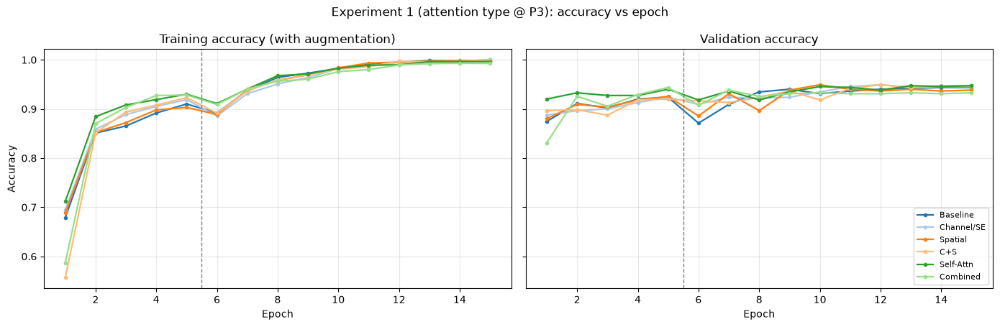

In [27]:
def curves(ax, names, key, title, ylabel):
    for n in names:
        h = R[n]["history"][key]; ax.plot(range(1, len(h) + 1), h, marker="o", ms=3, lw=1.6, color=COLORS[n], label=R[n]["short"])
    ax.axvline(R[names[0]]["phase1_epochs"] + 0.5, color="gray", ls="--", lw=1); ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.grid(alpha=.3)
_E1 = GROUPS["Exp1"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
curves(ax[0], _E1, "accuracy", "Training accuracy (with augmentation)", "Accuracy"); curves(ax[1], _E1, "val_accuracy", "Validation accuracy", "")
ax[1].legend(loc="lower right", fontsize=8); fig.suptitle("Experiment 1 (attention type @ P3): accuracy vs epoch"); fig.tight_layout(); show_save(fig, "fig02_accuracy_curves_exp1.png")

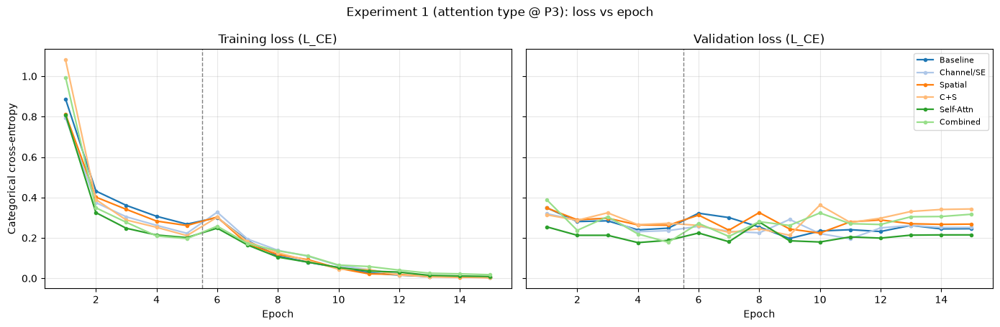

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
curves(ax[0], _E1, "loss", "Training loss (L_CE)", "Categorical cross-entropy"); curves(ax[1], _E1, "val_loss", "Validation loss (L_CE)", "")
ax[1].legend(loc="upper right", fontsize=8); fig.suptitle("Experiment 1 (attention type @ P3): loss vs epoch"); fig.tight_layout(); show_save(fig, "fig03_loss_curves_exp1.png")

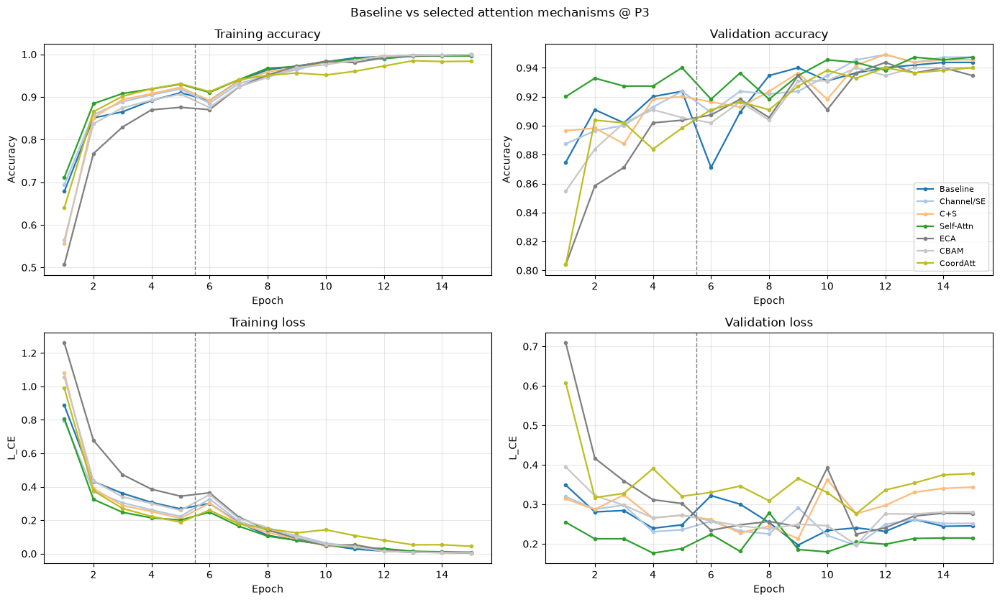

In [29]:
# Convergence comparison including the additional mechanisms (2x2 grid -> a single figure)
_CMP = ["A0_Baseline", "A1_Channel_P3", "A3_CS_P3", "A4_Self_P3", "X1_ECA_P3", "X2_CBAM_P3", "X3_Coord_P3"]
fig, ax = plt.subplots(2, 2, figsize=(14, 8.5))
curves(ax[0, 0], _CMP, "accuracy", "Training accuracy", "Accuracy"); curves(ax[0, 1], _CMP, "val_accuracy", "Validation accuracy", "Accuracy")
curves(ax[1, 0], _CMP, "loss", "Training loss", "L_CE"); curves(ax[1, 1], _CMP, "val_loss", "Validation loss", "L_CE")
ax[0, 1].legend(fontsize=8, loc="lower right"); fig.suptitle("Baseline vs selected attention mechanisms @ P3"); fig.tight_layout(); show_save(fig, "fig04_convergence_selected_models.png")

In [30]:
# Quantitative convergence behaviour (spec §19.2-5, §24.1: faster convergence? smoother? gap? overfitting? unstable?)
rows = []
for n in R:
    h = R[n]["history"]; va = np.array(h["val_accuracy"]); tr = np.array(h["accuracy"]); vl = np.array(h["val_loss"]); e1 = R[n]["phase1_epochs"]
    first = lambda th: (int(np.argmax(va >= th)) + 1) if (va >= th).any() else None
    rows.append({"Model": n, "epoch val>=85%": first(0.85), "epoch val>=90%": first(0.90), "best epoch": R[n]["best_epoch"],
                 "final train-val acc gap (pp)": round(100 * (tr[-1] - va[-1]), 2), "phase-2 val-acc roughness (pp)": round(100 * np.mean(np.abs(np.diff(va[e1 - 1:]))), 2),
                 "min val loss": round(float(vl.min()), 4), "final val loss": round(float(vl[-1]), 4), "val-loss rise from min": round(float(vl[-1] - vl.min()), 4),
                 "val acc @ end of phase 1 (%)": round(100 * va[e1 - 1], 2)})
CONV = pd.DataFrame(rows); show_table(CONV, "convergence_summary")

,Model,epoch val>=85%,epoch val>=90%,best epoch,final train-val acc gap (pp),phase-2 val-acc roughness (pp),min val loss,final val loss,val-loss rise from min,val acc @ end of phase 1 (%)
0,A0_Baseline,1,2,14,5.59,1.43,0.1969,0.2455,0.0486,92.38
1,A1_Channel_P3,1,3,12,5.22,0.67,0.1955,0.2518,0.0563,92.38
2,A2_Spatial_P3,1,2,10,6.05,1.94,0.2238,0.2682,0.0444,92.56
3,A3_CS_P3,1,4,12,5.37,0.87,0.2129,0.3433,0.1304,92.01
4,A4_Self_P3,1,1,13,4.91,1.05,0.1766,0.2148,0.0382,94.01
5,A5_Combined_P3,2,2,5,5.98,0.94,0.1783,0.3170,0.1387,94.37
6,B1_CS_P1,3,7,11,7.43,0.91,0.2831,0.3343,0.0512,87.66
7,B2_CS_P2,2,4,12,6.77,0.65,0.2295,0.3131,0.0836,90.02
8,B4_CS_P4,1,1,13,6.13,0.71,0.2641,0.2938,0.0297,91.83
9,M34_CS_P3P4,2,3,13,5.81,1.13,0.2318,0.2769,0.0452,92.38


## 6. Graphical performance analysis (spec §24.3–§24.6, §31-14)
Bars show the test-set value with the 95 % bootstrap interval (from the statistics cell). The y-axes of the bar graphs are truncated for readability — read heights relative to the baseline line, and relative to the error bars.

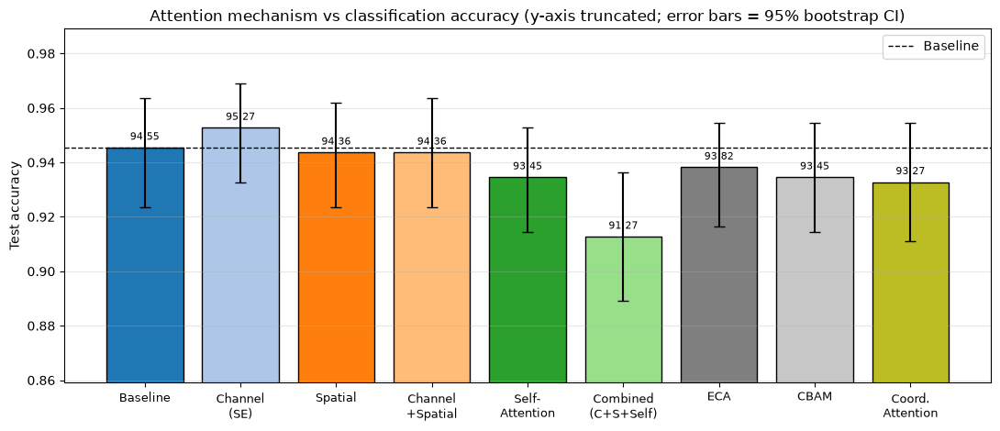

In [31]:
_MECH = ["A0_Baseline", "A1_Channel_P3", "A2_Spatial_P3", "A3_CS_P3", "A4_Self_P3", "A5_Combined_P3", "X1_ECA_P3", "X2_CBAM_P3", "X3_Coord_P3"]
_ML = {"A0_Baseline": "Baseline", "A1_Channel_P3": "Channel\n(SE)", "A2_Spatial_P3": "Spatial", "A3_CS_P3": "Channel\n+Spatial", "A4_Self_P3": "Self-\nAttention",
       "A5_Combined_P3": "Combined\n(C+S+Self)", "X1_ECA_P3": "ECA", "X2_CBAM_P3": "CBAM", "X3_Coord_P3": "Coord.\nAttention"}
def metric_bar(key, ylabel, fname, title):
    vals = np.array([R[n]["test"][{"acc": "accuracy", "f1": "f1"}[key]] for n in _MECH])
    lo = np.array([BOOT[n][key][0] for n in _MECH]); hi = np.array([BOOT[n][key][1] for n in _MECH])
    fig, ax = plt.subplots(figsize=(11, 4.8))
    bars = ax.bar(range(len(_MECH)), vals, yerr=[vals - lo, hi - vals], capsize=4, color=[COLORS[n] for n in _MECH], edgecolor="k")
    ax.axhline(vals[0], color="k", ls="--", lw=1, label="Baseline"); ax.set_xticks(range(len(_MECH))); ax.set_xticklabels([_ML[n] for n in _MECH], fontsize=9)
    ax.set_ylim(max(0, lo.min() - 0.03), min(1.0, hi.max() + 0.02)); ax.set_ylabel(ylabel); ax.set_title(title + " (y-axis truncated; error bars = 95% bootstrap CI)"); ax.grid(axis="y", alpha=.3)
    for b, v in zip(bars, vals): ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f"{100*v:.2f}", ha="center", va="bottom", fontsize=8)
    ax.legend(); fig.tight_layout(); show_save(fig, fname)
metric_bar("acc", "Test accuracy", "fig05_attention_vs_accuracy.png", "Attention mechanism vs classification accuracy")

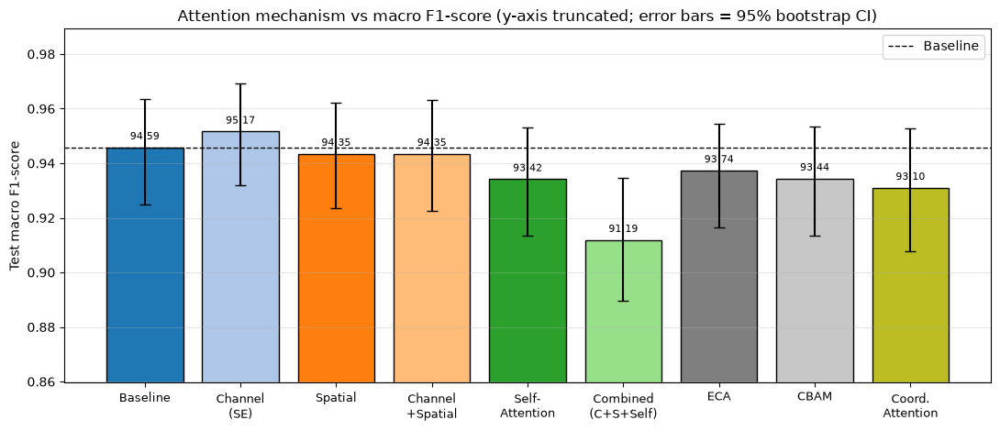

In [32]:
metric_bar("f1", "Test macro F1-score", "fig06_attention_vs_macro_f1.png", "Attention mechanism vs macro F1-score")

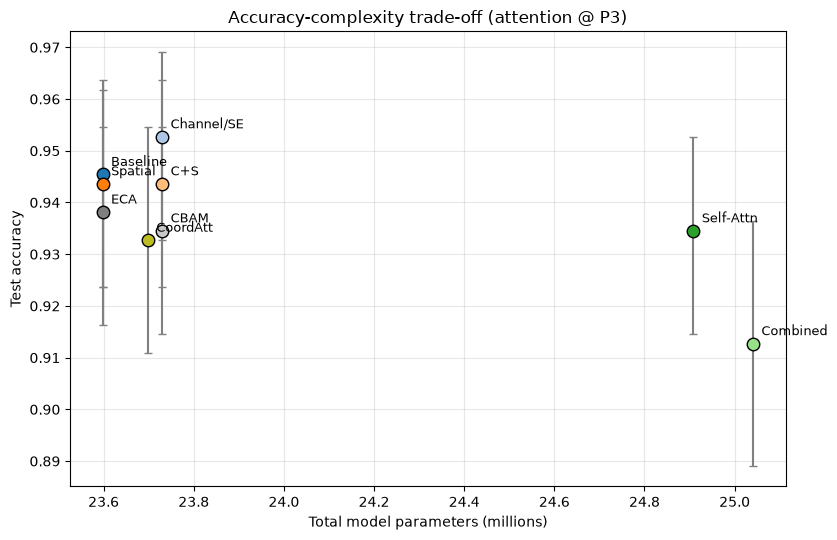

In [33]:
# §24.5 accuracy vs total parameters (one point per attention mechanism)
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for n in _MECH:
    x = R[n]["params_total"] / 1e6; y = R[n]["test"]["accuracy"]
    ax.errorbar(x, y, yerr=[[y - BOOT[n]["acc"][0]], [BOOT[n]["acc"][1] - y]], fmt="o", ms=9, color=COLORS[n], ecolor="gray", capsize=3, mec="k")
    ax.annotate(R[n]["short"], (x, y), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.set_xlabel("Total model parameters (millions)"); ax.set_ylabel("Test accuracy"); ax.set_title("Accuracy-complexity trade-off (attention @ P3)"); ax.grid(alpha=.3)
fig.tight_layout(); show_save(fig, "fig07_accuracy_vs_parameters.png")

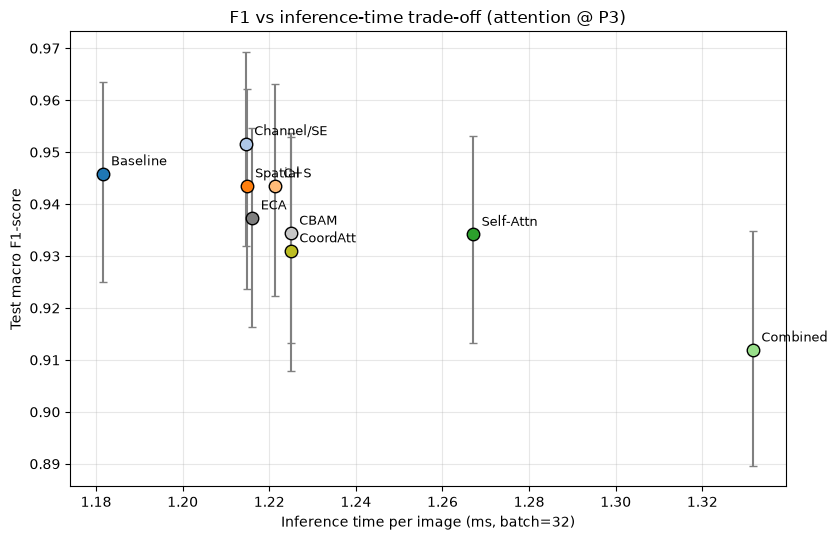

In [34]:
# §24.6 macro F1 vs inference time
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for n in _MECH:
    x = R[n]["inference_ms_bs32"]; y = R[n]["test"]["f1"]
    ax.errorbar(x, y, yerr=[[y - BOOT[n]["f1"][0]], [BOOT[n]["f1"][1] - y]], fmt="o", ms=9, color=COLORS[n], ecolor="gray", capsize=3, mec="k")
    ax.annotate(R[n]["short"], (x, y), textcoords="offset points", xytext=(6, 6), fontsize=9)
ax.set_xlabel("Inference time per image (ms, batch=32)"); ax.set_ylabel("Test macro F1-score"); ax.set_title("F1 vs inference-time trade-off (attention @ P3)"); ax.grid(alpha=.3)
fig.tight_layout(); show_save(fig, "fig08_f1_vs_inference_time.png")

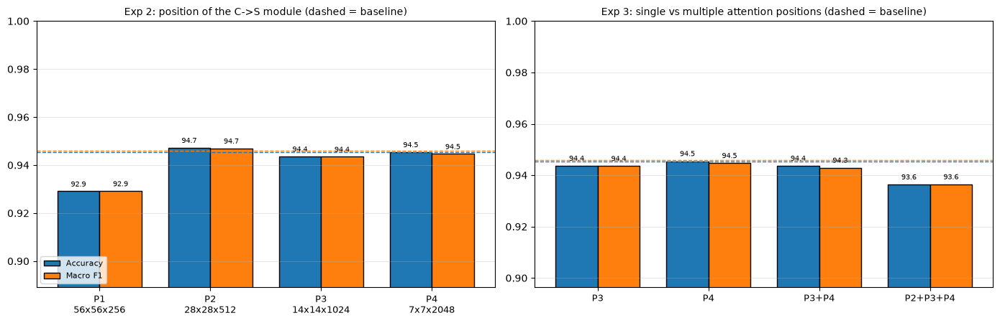

In [35]:
# Position (Exp 2) and multiple-position (Exp 3) comparison
def grouped(ax, names, labels, title, ref="A0_Baseline"):
    x = np.arange(len(names)); w = 0.38
    a = [R[n]["test"]["accuracy"] for n in names]; f = [R[n]["test"]["f1"] for n in names]
    ax.bar(x - w / 2, a, w, label="Accuracy", color="tab:blue", edgecolor="k"); ax.bar(x + w / 2, f, w, label="Macro F1", color="tab:orange", edgecolor="k")
    ax.axhline(R[ref]["test"]["accuracy"], color="tab:blue", ls="--", lw=1); ax.axhline(R[ref]["test"]["f1"], color="tab:orange", ls="--", lw=1)
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9); ax.set_title(title, fontsize=10); ax.grid(axis="y", alpha=.3)
    lo = min(min(a), min(f), R[ref]["test"]["accuracy"], R[ref]["test"]["f1"]); ax.set_ylim(max(0, lo - 0.04), 1.0)
    for i, (u, v) in enumerate(zip(a, f)): ax.text(i - w / 2, u + .002, f"{100*u:.1f}", ha="center", fontsize=7); ax.text(i + w / 2, v + .002, f"{100*v:.1f}", ha="center", fontsize=7)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
grouped(ax[0], ["B1_CS_P1", "B2_CS_P2", "A3_CS_P3", "B4_CS_P4"], ["P1\n56x56x256", "P2\n28x28x512", "P3\n14x14x1024", "P4\n7x7x2048"], "Exp 2: position of the C->S module (dashed = baseline)")
_mn = ["A3_CS_P3", "B4_CS_P4", "M34_CS_P3P4"] + [n for n in ["M234_CS_P2P3P4"] if n in R]
grouped(ax[1], _mn, ["P3", "P4", "P3+P4", "P2+P3+P4"][:len(_mn)], "Exp 3: single vs multiple attention positions (dashed = baseline)")
ax[0].legend(fontsize=8, loc="lower left"); fig.tight_layout(); show_save(fig, "fig09_position_and_multiposition.png")

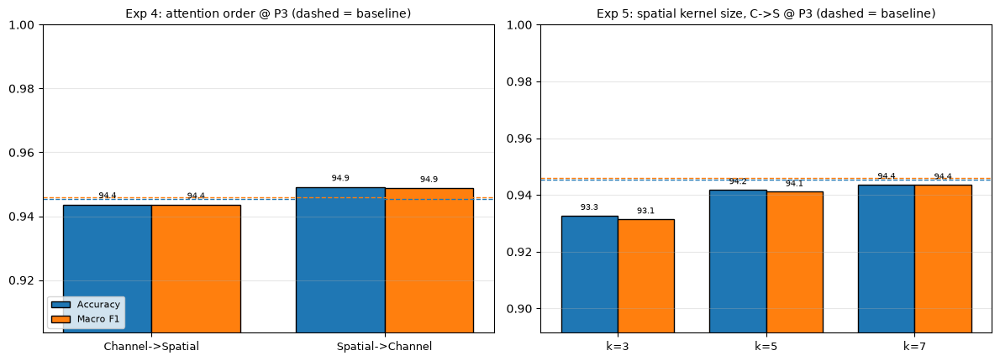

In [36]:
# Attention order (Exp 4) and kernel size (Exp 5)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
grouped(ax[0], ["A3_CS_P3", "O1_SC_P3"], ["Channel->Spatial", "Spatial->Channel"], "Exp 4: attention order @ P3 (dashed = baseline)")
grouped(ax[1], ["K3_CS_P3", "K5_CS_P3", "A3_CS_P3"], ["k=3", "k=5", "k=7"], "Exp 5: spatial kernel size, C->S @ P3 (dashed = baseline)")
ax[0].legend(fontsize=8, loc="lower left"); fig.tight_layout(); show_save(fig, "fig10_order_and_kernel.png")

## 7. Confusion-matrix analysis (spec §25, §31-4)
Baseline vs the **selected attention model** (`SELECTED_MODEL`, fixed a priori as the principal module of the experiment: Channel→Spatial @ P3, i.e. `A3`; it was not chosen using test results). The third panel is the difference (attention − baseline).

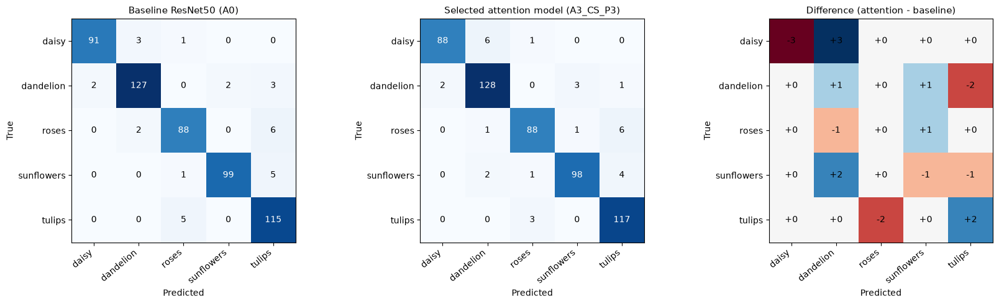

In [37]:
def cm_of(n): return np.array(R[n]["test"]["confusion"])
cm0, cm1 = cm_of("A0_Baseline"), cm_of(SELECTED_MODEL)
fig, ax = plt.subplots(1, 3, figsize=(17, 5))
for a, (cm, ttl, cmap) in zip(ax, [(cm0, "Baseline ResNet50 (A0)", "Blues"), (cm1, f"Selected attention model ({SELECTED_MODEL})", "Blues"), (cm1 - cm0, "Difference (attention - baseline)", "RdBu")]):
    vmax = np.abs(cm).max() if cmap == "RdBu" else None
    im = a.imshow(cm, cmap=cmap, vmin=-vmax if vmax else None, vmax=vmax)
    a.set_xticks(range(NUM_CLASSES)); a.set_yticks(range(NUM_CLASSES)); a.set_xticklabels(CLASS_NAMES, rotation=40, ha="right"); a.set_yticklabels(CLASS_NAMES)
    a.set_xlabel("Predicted"); a.set_ylabel("True"); a.set_title(ttl, fontsize=11)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            v = cm[i, j]; a.text(j, i, f"{v:+d}" if cmap == "RdBu" else str(v), ha="center", va="center", fontsize=10,
                                 color="white" if (cmap != "RdBu" and v > cm.max() / 2) else "black")
fig.tight_layout(); show_save(fig, "fig11_confusion_matrices.png")

In [38]:
# class-wise analysis: which classes are best / confused / benefit from attention? (spec §25 bullets)
def pc(n, k): return np.array(R[n]["test"]["per_class"][k])
rows = []
for c, cn in enumerate(CLASS_NAMES):
    rows.append({"Class": cn, "Support": int(pc("A0_Baseline", "support")[c]),
                 "Recall A0 (%)": pct(pc("A0_Baseline", "recall")[c]), f"Recall {SELECTED_MODEL} (%)": pct(pc(SELECTED_MODEL, "recall")[c]),
                 "dRecall (pp)": f"{100*(pc(SELECTED_MODEL,'recall')[c]-pc('A0_Baseline','recall')[c]):+.2f}",
                 "F1 A0 (%)": pct(pc("A0_Baseline", "f1")[c]), f"F1 {SELECTED_MODEL} (%)": pct(pc(SELECTED_MODEL, "f1")[c]),
                 "dF1 (pp)": f"{100*(pc(SELECTED_MODEL,'f1')[c]-pc('A0_Baseline','f1')[c]):+.2f}"})
CLASSWISE = pd.DataFrame(rows); show_table(CLASSWISE, "classwise_baseline_vs_selected")
def top_conf(cm, k=5):
    off = [(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i, j] > 0]
    return sorted(off, reverse=True)[:k]
print("Most frequent confusions  (count, true -> predicted)")
print("  baseline :", [(int(a), f"{b}->{c}") for a, b, c in top_conf(cm0)])
print(f"  {SELECTED_MODEL}:", [(int(a), f"{b}->{c}") for a, b, c in top_conf(cm1)])
print("Errors baseline:", int(cm0.sum() - np.trace(cm0)), "| errors selected:", int(cm1.sum() - np.trace(cm1)))
print("\nFull classification report, selected model:"); print(classification_report(y_test, PRED[SELECTED_MODEL], target_names=CLASS_NAMES, digits=4, zero_division=0))

,Class,Support,Recall A0 (%),Recall A3_CS_P3 (%),dRecall (pp),F1 A0 (%),F1 A3_CS_P3 (%),dF1 (pp)
0,daisy,95,95.79,92.63,-3.16,96.81,95.14,-1.67
1,dandelion,134,94.78,95.52,+0.75,95.49,94.46,-1.02
2,roses,96,91.67,91.67,+0.00,92.15,93.12,+0.98
3,sunflowers,105,94.29,93.33,-0.95,96.12,94.69,-1.43
4,tulips,120,95.83,97.50,+1.67,92.37,94.35,+1.99


Most frequent confusions  (count, true -> predicted)
  baseline : [(6, 'roses->tulips'), (5, 'tulips->roses'), (5, 'sunflowers->tulips'), (3, 'dandelion->tulips'), (3, 'daisy->dandelion')]
  A3_CS_P3: [(6, 'roses->tulips'), (6, 'daisy->dandelion'), (4, 'sunflowers->tulips'), (3, 'tulips->roses'), (3, 'dandelion->sunflowers')]
Errors baseline: 30 | errors selected: 31

Full classification report, selected model:
              precision    recall  f1-score   support

       daisy     0.9778    0.9263    0.9514        95
   dandelion     0.9343    0.9552    0.9446       134
       roses     0.9462    0.9167    0.9312        96
  sunflowers     0.9608    0.9333    0.9469       105
      tulips     0.9141    0.9750    0.9435       120

    accuracy                         0.9436       550
   macro avg     0.9466    0.9413    0.9435       550
weighted avg     0.9445    0.9436    0.9436       550



## 8. Qualitative and interpretability analysis (spec §26–§32, §31-5…13)
**Important distinction used throughout:** *internal attention maps* (channel weights, spatial maps, self-attention matrices) are tensors actually computed in the forward pass; **Grad-CAM** is a post-hoc gradient-based explanation of the final feature map. Neither is proof of "what the network understands" — they are evidence to be read together with the quantitative results and the proxy statistics below.

The five qualitative images are selected by a **fixed, seeded rule that does not look at attention maps**: 3 test images that both baseline and selected model classify correctly (from different classes when possible) and 2 images that are misclassified (preferably by both). Quantitative proxy statistics are computed on the **whole test set** so that no conclusion rests on a handful of pictures.

In [39]:
# ============================ MODEL LOADING + VISUALISATION HELPERS ============================
_MODEL_CACHE, _SUB = {}, {}
def get_model(name):
    if name not in _MODEL_CACHE:
        m, t = build_model(EXPERIMENTS[name]["att"], weights=None); m.load_weights(paths(name)["w"]); _MODEL_CACHE[name] = (m, t)
    return _MODEL_CACHE[name]
def get_sub(name, tap):
    if (name, tap) not in _SUB: m, t = get_model(name); _SUB[(name, tap)] = keras.Model(m.input, t[tap])
    return _SUB[(name, tap)]
def get_gc(name):
    if (name, "gc") not in _SUB:
        m, _ = get_model(name); _SUB[(name, "gc")] = keras.Model(m.input, [m.get_layer("final_features").output, m.get_layer("logits").output])
    return _SUB[(name, "gc")]

def up(m): return tf.image.resize(np.asarray(m, dtype="float32")[..., None], (IMG_SIZE, IMG_SIZE), method="bilinear").numpy()[..., 0]
def norm01(m): m = np.asarray(m, dtype="float32"); return (m - m.min()) / (m.max() - m.min() + 1e-8)

def gradcam(name, X, bs=32, stats=False):
    """Grad-CAM of the PREDICTED class on the last feature map ('final_features', input of GAP): alpha_k = mean grad, cam = ReLU(sum_k alpha_k A_k)."""
    gm = get_gc(name); cams, preds, st = [], [], []
    for i in range(0, len(X), bs):
        x = tf.constant(pp(X[i:i + bs]))
        with tf.GradientTape() as tape:
            A, lg = gm(x, training=False); cls = tf.argmax(lg, axis=1); score = tf.gather(lg, cls, batch_dims=1)
        g = tape.gradient(score, A); alpha = tf.reduce_mean(g, axis=[1, 2], keepdims=True)
        cam = tf.nn.relu(tf.reduce_sum(alpha * A, axis=-1))
        cam = tf.image.resize(cam[..., None], (IMG_SIZE, IMG_SIZE), method="bilinear")[..., 0]
        cam = (cam / (tf.reduce_max(cam, axis=[1, 2], keepdims=True) + 1e-8)).numpy(); preds.append(cls.numpy())
        if stats:
            N = len(cam); flat = cam.reshape(N, -1); p = flat / (flat.sum(1, keepdims=True) + 1e-8); c0, c1 = IMG_SIZE // 4, 3 * IMG_SIZE // 4
            st.append(np.stack([(flat >= 0.5).mean(1), -(p * np.log(p + 1e-12)).sum(1) / np.log(flat.shape[1]),
                                cam[:, c0:c1, c0:c1].reshape(N, -1).sum(1) / (flat.sum(1) + 1e-8)], 1))
        else: cams.append(cam)
    return (np.concatenate(st), np.concatenate(preds)) if stats else (np.concatenate(cams), np.concatenate(preds))

def att_maps(name, pos, X, keys, bs=32):
    """Internal attention tensors of the attention block at position `pos`, computed from the true pre-attention features."""
    m, _ = get_model(name); sub = get_sub(name, f"P{pos}_pre"); layer = m.get_layer(f"att_P{pos}"); out = {k: [] for k in keys}
    for i in range(0, len(X), bs):
        mp = layer.internal_maps(sub(pp(X[i:i + bs]), training=False))
        for k in keys: out[k].append(mp[k].numpy())
    return {k: np.concatenate(v) for k, v in out.items()}

def sa_response_ratio(name, pos, X, bs=32):
    """||gamma * Y W_O|| / ||F_in|| per spatial location: how much the self-attention branch actually changes the feature."""
    m, _ = get_model(name); sub = get_sub(name, f"P{pos}_pre"); layer = m.get_layer(f"att_P{pos}"); out = []
    for i in range(0, len(X), bs):
        xin = layer.internal_maps(sub(pp(X[i:i + bs]), training=False))["self_input"]
        out.append((tf.norm(layer.sa.response(xin), axis=-1) / (tf.norm(xin, axis=-1) + 1e-8)).numpy())
    return np.concatenate(out)

def ov(ax, i, heat, title=None, alpha=0.5, cmap="jet"):
    ax.imshow(X_test[i]); ax.imshow(heat, cmap=cmap, alpha=alpha, vmin=0, vmax=1); ax.axis("off")
    if title: ax.set_title(title, fontsize=8)
def lab(n, i): return f"{CLASS_NAMES[PRED[n][i]]} ({'ok' if PRED[n][i] == y_test[i] else 'wrong'})"

# safety check: re-loaded weights must reproduce the saved test predictions
for n in ["A0_Baseline", SELECTED_MODEL]:
    d = np.abs(predict_probs(get_model(n)[0], X_test[:64]) - PROBS[n][:64]).max()
    print(f"[reload check] {n}: max |p_reloaded - p_saved| = {d:.1e}"); assert d < 5e-3, "weights did not reload correctly"

[reload check] A0_Baseline: max |p_reloaded - p_saved| = 0.0e+00


[reload check] A3_CS_P3: max |p_reloaded - p_saved| = 0.0e+00


In [40]:
# ============================ SELECTION OF THE QUALITATIVE EXAMPLES (fixed rule, seeded, independent of attention maps) ============================
def select_images():
    rs = np.random.default_rng(SEED); p0, ps = PRED["A0_Baseline"], PRED[SELECTED_MODEL]; allidx = np.arange(len(y_test))
    ok_both = allidx[(p0 == y_test) & (ps == y_test)]; ok_sel = allidx[ps == y_test]
    ok = []
    for c in rs.permutation(NUM_CLASSES):                                   # one correctly-classified image from up to 3 different classes
        cand = ok_both[y_test[ok_both] == c]
        if len(cand) and len(ok) < 3: ok.append(int(rs.choice(cand)))
    for pool in (ok_both, ok_sel, allidx):                                  # fall-backs (only relevant for tiny / smoke-test runs)
        for i in rs.permutation(pool):
            if len(ok) < 3 and int(i) not in ok: ok.append(int(i))
    tiers = [allidx[(p0 != y_test) & (ps != y_test)], allidx[(ps != y_test) & (p0 == y_test)], allidx[(p0 != y_test) & (ps == y_test)], allidx]
    bad = []; pooled = [int(i) for t in tiers for i in rs.permutation(t) if int(i) not in ok]
    for i in pooled:                                                         # prefer different true classes
        if len(bad) < 2 and (not bad or y_test[i] != y_test[bad[0]]): bad.append(i)
    for i in pooled:
        if len(bad) < 2 and i not in bad: bad.append(i)
    return ok, bad
IDX_OK, IDX_BAD = select_images(); IDX_ALL = IDX_OK + IDX_BAD
_M = ["A0_Baseline", "A1_Channel_P3", "A2_Spatial_P3", "A3_CS_P3", "A4_Self_P3", "A5_Combined_P3", "X1_ECA_P3", "X2_CBAM_P3", "X3_Coord_P3"]
rows = [{"test idx": i, "kind": "correct (both A0 & selected)" if i in IDX_OK else "misclassified", "true class": CLASS_NAMES[y_test[i]],
         **{R[n]["short"]: CLASS_NAMES[PRED[n][i]] + ("" if PRED[n][i] == y_test[i] else " *") for n in _M}} for i in IDX_ALL]
SELECTION = pd.DataFrame(rows); show_table(SELECTION, "qualitative_image_selection")
print("(* = misclassified by that model.)  Fixed images used in every qualitative figure:", IDX_ALL)

,test idx,kind,true class,Baseline,Channel/SE,Spatial,C+S,Self-Attn,Combined,ECA,CBAM,CoordAtt
0,258,correct (both A0 & selected),tulips,tulips,tulips,tulips,tulips,tulips,tulips,tulips,tulips,tulips
1,460,correct (both A0 & selected),roses,roses,roses,roses,roses,roses,roses,roses,roses,roses
2,59,correct (both A0 & selected),sunflowers,sunflowers,sunflowers,sunflowers,sunflowers,sunflowers,sunflowers,sunflowers,sunflowers,sunflowers
3,19,misclassified,tulips,roses *,tulips,roses *,roses *,roses *,tulips,roses *,tulips,tulips
4,334,misclassified,roses,tulips *,tulips *,tulips *,tulips *,tulips *,tulips *,tulips *,tulips *,tulips *


(* = misclassified by that model.)  Fixed images used in every qualitative figure: [258, 460, 59, 19, 334]


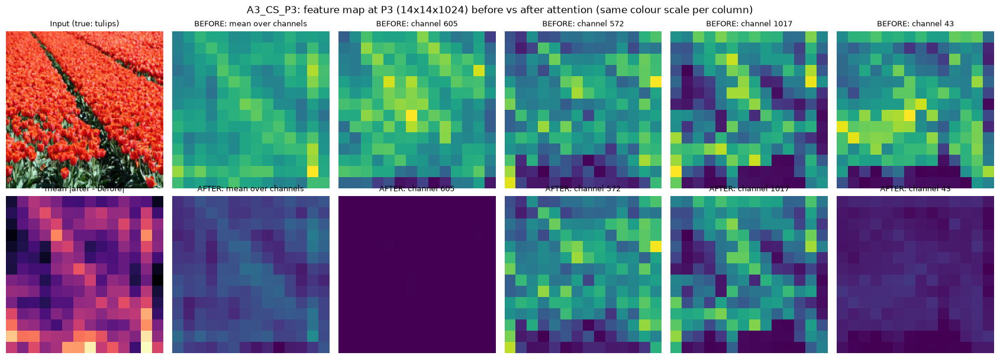

In [41]:
# ============================ FIG: feature maps BEFORE vs AFTER attention (spec §26, §31-5 and §31-10) ============================
name, pos, i = SELECTED_MODEL, int(EXPERIMENTS[SELECTED_MODEL]["pos"][1]), IDX_OK[0]
x = pp(X_test[i:i + 1]); pre = get_sub(name, f"P{pos}_pre")(x, training=False).numpy()[0]; post = get_sub(name, f"P{pos}_post")(x, training=False).numpy()[0]
top = np.argsort(-pre.mean((0, 1)))[:4]                                        # the 4 channels with the highest mean pre-attention activation
cols = [("mean over channels", pre.mean(-1), post.mean(-1))] + [(f"channel {c}", pre[..., c], post[..., c]) for c in top]
fig, ax = plt.subplots(2, 6, figsize=(17, 6.2))
ax[0, 0].imshow(X_test[i]); ax[0, 0].set_title(f"Input (true: {CLASS_NAMES[y_test[i]]})", fontsize=9)
d = np.abs(post - pre).mean(-1); ax[1, 0].imshow(d, cmap="magma"); ax[1, 0].set_title("mean |after - before|", fontsize=9)
for j, (t, a, b) in enumerate(cols, start=1):
    lo, hi = min(a.min(), b.min()), max(a.max(), b.max())
    ax[0, j].imshow(a, cmap="viridis", vmin=lo, vmax=hi); ax[1, j].imshow(b, cmap="viridis", vmin=lo, vmax=hi)
    ax[0, j].set_title(f"BEFORE: {t}", fontsize=9); ax[1, j].set_title(f"AFTER: {t}", fontsize=9)
for a in ax.ravel(): a.axis("off")
fig.suptitle(f"{name}: feature map at P{pos} ({pre.shape[0]}x{pre.shape[1]}x{pre.shape[2]}) before vs after attention (same colour scale per column)")
fig.tight_layout(); show_save(fig, "fig12_feature_maps_before_after_attention.png")

### 8.1 Channel-attention weights (spec §28.1, §31-6)

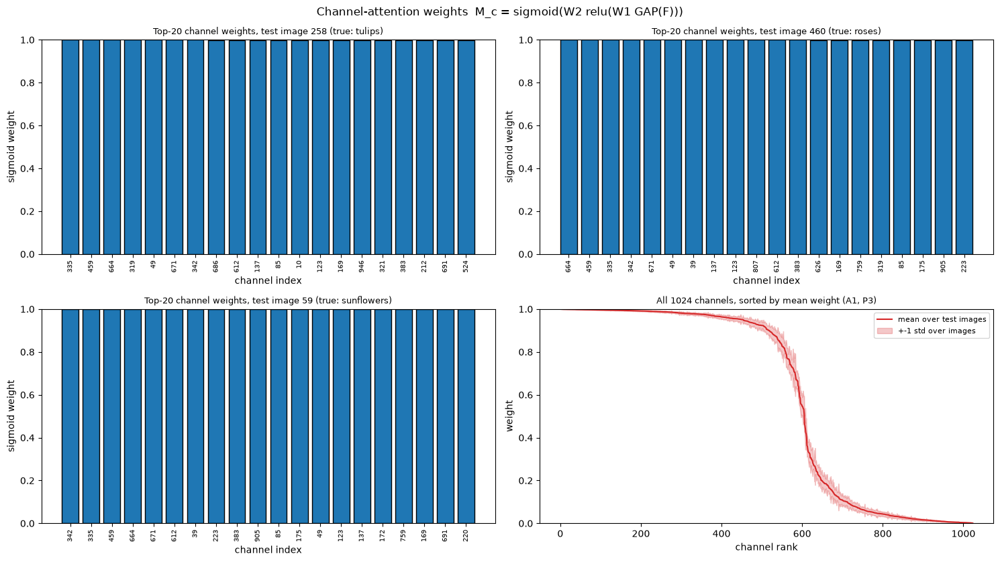

In [42]:
# Channel weights of the pure channel-attention model A1 (SE-style, P3). Top-20 channels for three images + distribution over the whole test set.
W = att_maps("A1_Channel_P3", 3, X_test, ["channel"])["channel"].reshape(len(X_test), -1)         # (N, C)
fig, ax = plt.subplots(2, 2, figsize=(15, 8.5))
for a, i in zip(ax.ravel()[:3], IDX_OK):
    w = W[i]; t = np.argsort(-w)[:20]
    a.bar(range(20), w[t], color="tab:blue", edgecolor="k"); a.set_xticks(range(20)); a.set_xticklabels(t, rotation=90, fontsize=7)
    a.set_ylim(0, 1); a.set_title(f"Top-20 channel weights, test image {i} (true: {CLASS_NAMES[y_test[i]]})", fontsize=9); a.set_ylabel("sigmoid weight"); a.set_xlabel("channel index")
mu, sd = W.mean(0), W.std(0); o = np.argsort(-mu); a = ax[1, 1]
a.plot(mu[o], color="tab:red", label="mean over test images"); a.fill_between(range(len(o)), (mu - sd)[o], (mu + sd)[o], color="tab:red", alpha=.25, label="+-1 std over images")
a.set_ylim(0, 1); a.set_title(f"All {W.shape[1]} channels, sorted by mean weight (A1, P3)", fontsize=9); a.set_xlabel("channel rank"); a.set_ylabel("weight"); a.legend(fontsize=8)
fig.suptitle("Channel-attention weights  M_c = sigmoid(W2 relu(W1 GAP(F)))"); fig.tight_layout(); show_save(fig, "fig13_channel_attention_weights.png")

In [43]:
# Quantitative channel-weight statistics over the whole test set (is attention selective? does it depend on the input image?)
def channel_stats(name, pos):
    W = att_maps(name, pos, X_test, ["channel"])["channel"].reshape(len(X_test), -1); k = max(1, W.shape[1] // 10)
    s = np.corrcoef(W[:100]); off = s[~np.eye(len(s), dtype=bool)]
    return {"Model": name, "mean weight": round(float(W.mean()), 3), "std across channels": round(float(W.std(1).mean()), 3),
            "std across images": round(float(W.std(0).mean()), 4), "frac channels > 0.5": round(float((W > 0.5).mean()), 3),
            "top-10% channels' share of weight": round(float(np.sort(W, 1)[:, -k:].sum(1).mean() / W.sum(1).mean()), 3),
            "mean corr between images": round(float(np.nanmean(off)), 3)}
CHSTAT = pd.DataFrame([channel_stats(n, int(EXPERIMENTS[n]["pos"][1])) for n in ["A1_Channel_P3", "A3_CS_P3", "O1_SC_P3", "X1_ECA_P3", "X2_CBAM_P3", "A5_Combined_P3"]])
show_table(CHSTAT, "channel_weight_statistics")
print("Reading guide: 'std across channels' = how selective the weighting is inside one image; 'std across images' and 'mean corr between images' = how much the "
      "weighting depends on the input (corr close to 1 -> nearly the same channel weighting for every image, i.e. close to a static re-scaling).")

,Model,mean weight,std across channels,std across images,frac channels > 0.5,top-10% channels' share of weight,mean corr between images
0,A1_Channel_P3,0.590,0.438,0.0134,0.590,0.168,0.998
1,A3_CS_P3,0.599,0.390,0.0369,0.611,0.165,0.981
2,O1_SC_P3,0.603,0.404,0.0274,0.611,0.164,0.990
3,X1_ECA_P3,0.527,0.077,0.0552,0.620,0.129,0.437
4,X2_CBAM_P3,0.564,0.490,0.0079,0.563,0.177,0.994
5,A5_Combined_P3,0.552,0.322,0.0468,0.574,0.175,0.969


Reading guide: 'std across channels' = how selective the weighting is inside one image; 'std across images' and 'mean corr between images' = how much the weighting depends on the input (corr close to 1 -> nearly the same channel weighting for every image, i.e. close to a static re-scaling).


### 8.2 Spatial-attention maps (spec §28.2, §29, §31-7/8/13)
The heat map shows the sigmoid spatial map `M_s` actually computed by the module (min–max normalised per image for display; the raw range is printed in the title because a map that is almost uniform is *not* a strong spatial selection). The overlay uses the normalised map.

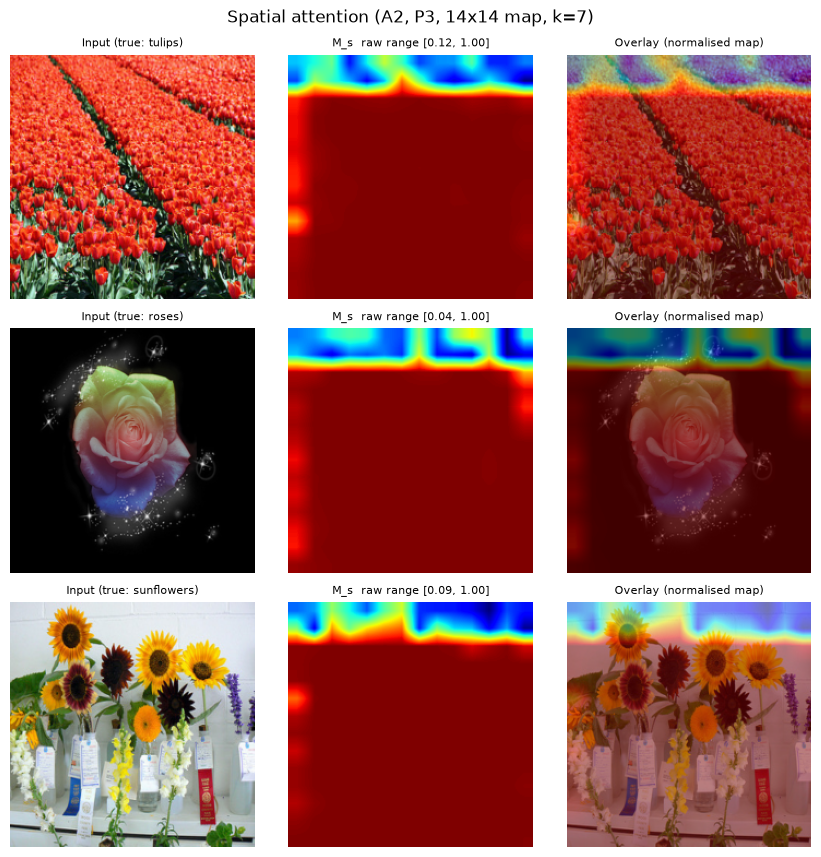

In [44]:
def spatial_figure(name, fname, title):
    pos = int(EXPERIMENTS[name]["pos"][1]); S = att_maps(name, pos, X_test[IDX_OK], ["spatial"])["spatial"][..., 0]
    fig, ax = plt.subplots(len(IDX_OK), 3, figsize=(8.5, 2.9 * len(IDX_OK)))
    for r, i in enumerate(IDX_OK):
        ax[r, 0].imshow(X_test[i]); ax[r, 0].set_title(f"Input (true: {CLASS_NAMES[y_test[i]]})", fontsize=8)
        ax[r, 1].imshow(up(norm01(S[r])), cmap="jet", vmin=0, vmax=1); ax[r, 1].set_title(f"M_s  raw range [{S[r].min():.2f}, {S[r].max():.2f}]", fontsize=8)
        ov(ax[r, 2], i, up(norm01(S[r])), "Overlay (normalised map)")
        for a in ax[r]: a.axis("off")
    fig.suptitle(title); fig.tight_layout(); show_save(fig, fname)
spatial_figure("A2_Spatial_P3", "fig14_spatial_attention_A2.png", "Spatial attention (A2, P3, 14x14 map, k=7)")

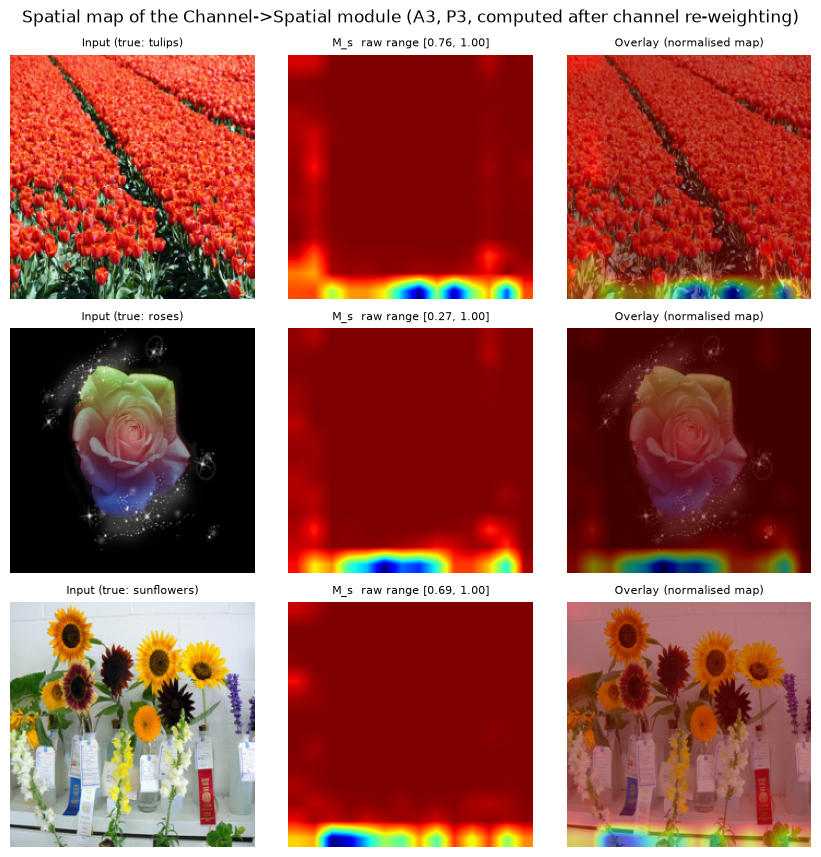

In [45]:
spatial_figure("A3_CS_P3", "fig15_spatial_attention_A3_after_channel.png", "Spatial map of the Channel->Spatial module (A3, P3, computed after channel re-weighting)")

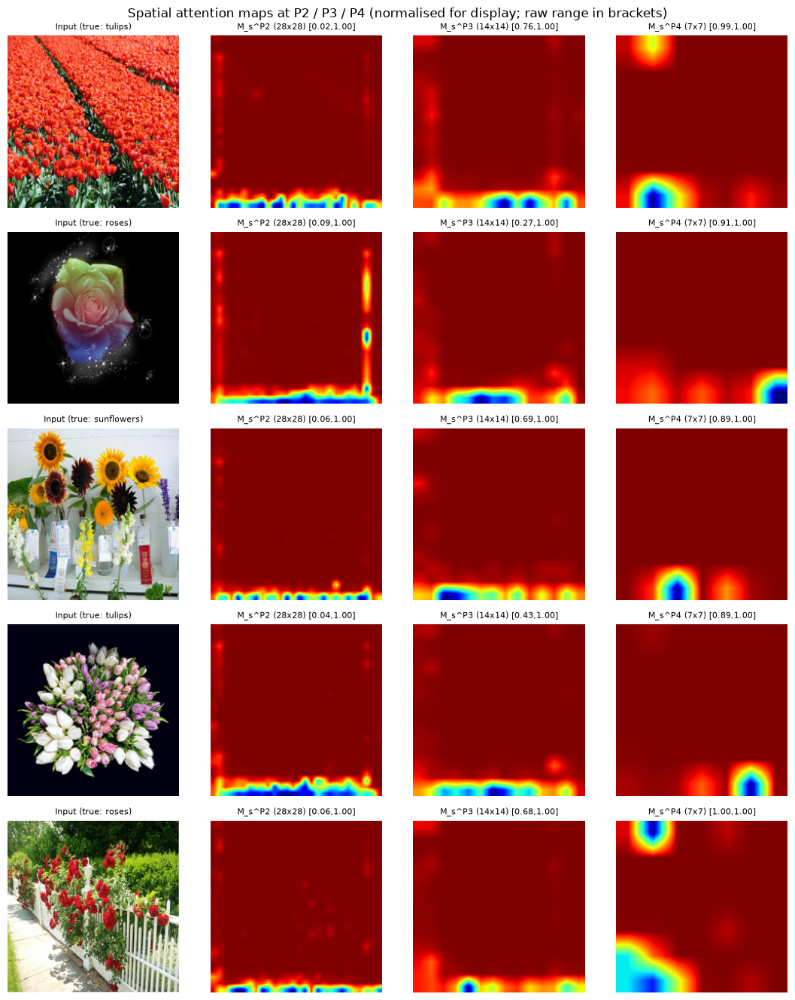

In [46]:
# Spatial maps at different network depths (spec §29: Input | M_s^P2 | M_s^P3 | M_s^P4); same C->S module, same images
_pm = [("B2_CS_P2", 2), ("A3_CS_P3", 3), ("B4_CS_P4", 4)]
SM = {p: att_maps(n, p, X_test[IDX_ALL], ["spatial"])["spatial"][..., 0] for n, p in _pm}
fig, ax = plt.subplots(len(IDX_ALL), 4, figsize=(11, 2.7 * len(IDX_ALL)))
for r, i in enumerate(IDX_ALL):
    ax[r, 0].imshow(X_test[i]); ax[r, 0].set_title(f"Input (true: {CLASS_NAMES[y_test[i]]})", fontsize=8)
    for c, (n, p) in enumerate(_pm, start=1):
        ax[r, c].imshow(up(norm01(SM[p][r])), cmap="jet", vmin=0, vmax=1)
        ax[r, c].set_title(f"M_s^P{p} ({SM[p].shape[1]}x{SM[p].shape[2]}) [{SM[p][r].min():.2f},{SM[p][r].max():.2f}]", fontsize=8)
    for a in ax[r]: a.axis("off")
fig.suptitle("Spatial attention maps at P2 / P3 / P4 (normalised for display; raw range in brackets)"); fig.tight_layout(); show_save(fig, "fig16_spatial_maps_across_positions.png")

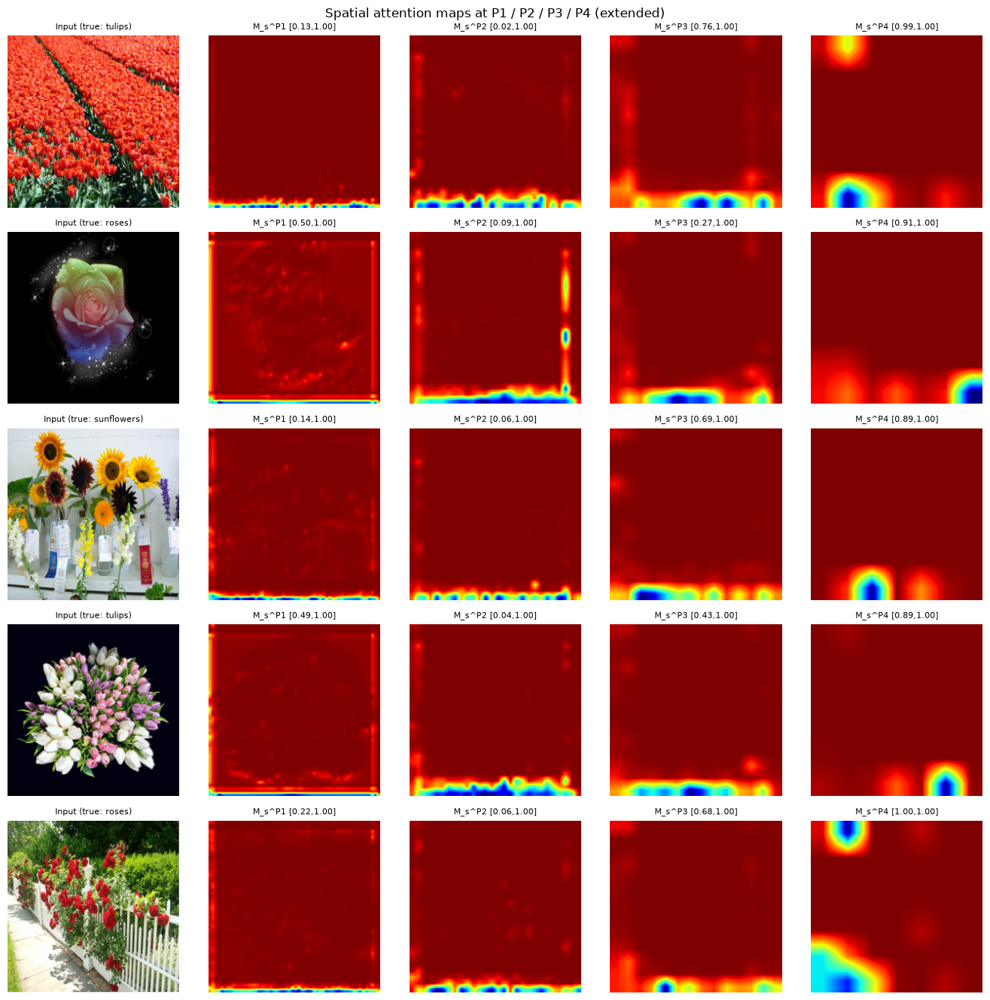

In [47]:
# Same, including the earliest position P1 (56x56) that is not part of the §29 layout
_pm4 = [("B1_CS_P1", 1)] + _pm
SM[1] = att_maps("B1_CS_P1", 1, X_test[IDX_ALL], ["spatial"])["spatial"][..., 0]
fig, ax = plt.subplots(len(IDX_ALL), 5, figsize=(13.5, 2.7 * len(IDX_ALL)))
for r, i in enumerate(IDX_ALL):
    ax[r, 0].imshow(X_test[i]); ax[r, 0].set_title(f"Input (true: {CLASS_NAMES[y_test[i]]})", fontsize=8)
    for c, (n, p) in enumerate(_pm4, start=1):
        ax[r, c].imshow(up(norm01(SM[p][r])), cmap="jet", vmin=0, vmax=1); ax[r, c].set_title(f"M_s^P{p} [{SM[p][r].min():.2f},{SM[p][r].max():.2f}]", fontsize=8)
    for a in ax[r]: a.axis("off")
fig.suptitle("Spatial attention maps at P1 / P2 / P3 / P4 (extended)"); fig.tight_layout(); show_save(fig, "fig17_spatial_maps_P1_to_P4.png")

In [48]:
# Whole-test-set statistics of the spatial maps: strength, selectivity, centre bias, consistency across images (spec §28.2 / §29 analysis)
def spatial_stats(name):
    pos = int(EXPERIMENTS[name]["pos"][1]); S = att_maps(name, pos, X_test, ["spatial"])["spatial"][..., 0]; N, h, w = S.shape
    flat = S.reshape(N, -1); nm = (flat - flat.min(1, keepdims=True)) / (flat.max(1, keepdims=True) - flat.min(1, keepdims=True) + 1e-8)
    p = flat / flat.sum(1, keepdims=True); ent = -(p * np.log(p + 1e-12)).sum(1) / np.log(h * w)
    cen = S[:, h // 4: 3 * h // 4, w // 4: 3 * w // 4].reshape(N, -1).sum(1) / flat.sum(1)
    s = np.corrcoef(flat[:100]); off = s[~np.eye(len(s), dtype=bool)]
    return {"Model": name, "Position": f"P{pos} ({h}x{w})", "raw mean": round(float(flat.mean()), 3), "mean contrast (max-min)": round(float((flat.max(1) - flat.min(1)).mean()), 3),
            "norm. entropy (1=uniform)": round(float(ent.mean()), 4), "coverage of norm. map >= 0.5": round(float((nm >= .5).mean()), 3),
            "centre-box share (uniform = 0.25)": round(float(cen.mean()), 3), "mean corr between images": round(float(np.nanmean(off)), 3)}
SPSTAT = pd.DataFrame([spatial_stats(n) for n in ["B1_CS_P1", "B2_CS_P2", "A3_CS_P3", "B4_CS_P4", "A2_Spatial_P3", "O1_SC_P3", "K3_CS_P3", "K5_CS_P3", "X2_CBAM_P3"]])
show_table(SPSTAT, "spatial_map_statistics")
print("Reading guide: 'mean contrast' near 0 means the module barely discriminates between locations. 'centre-box share' compares the attention mass in the central 50%x50% box "
      "with the 0.25 expected from a uniform map: tf_flowers subjects are usually (not always) centred, so this is only a rough proxy for foreground focus, NOT a measured foreground metric.")

,Model,Position,raw mean,mean contrast (max-min),norm. entropy (1=uniform),coverage of norm. map >= 0.5,centre-box share (uniform = 0.25),mean corr between images
0,B1_CS_P1,P1 (56x56),0.978,0.725,0.9996,0.985,0.254,0.899
1,B2_CS_P2,P2 (28x28),0.968,0.875,0.9985,0.971,0.258,0.863
2,A3_CS_P3,P3 (14x14),0.985,0.374,0.9997,0.974,0.254,0.690
3,B4_CS_P4,P4 (7x7),0.995,0.152,0.9996,0.968,0.328,0.303
4,A2_Spatial_P3,P3 (14x14),0.903,0.920,0.9914,0.885,0.277,0.897
5,O1_SC_P3,P3 (14x14),0.937,0.852,0.9959,0.931,0.267,0.838
6,K3_CS_P3,P3 (14x14),0.742,0.917,0.9904,0.883,0.262,0.650
7,K5_CS_P3,P3 (14x14),0.974,0.563,0.9992,0.966,0.256,0.764
8,X2_CBAM_P3,P3 (14x14),0.987,0.344,0.9998,0.977,0.253,0.644


Reading guide: 'mean contrast' near 0 means the module barely discriminates between locations. 'centre-box share' compares the attention mass in the central 50%x50% box with the 0.25 expected from a uniform map: tf_flowers subjects are usually (not always) centred, so this is only a rough proxy for foreground focus, NOT a measured foreground metric.


### 8.3 Self-attention response (spec §12, §28.3, §31-9)
`A` is the 196×196 attention matrix (14×14 locations at P3). The figure shows (i) where the **centre-location query** looks, (ii) how much attention each location **receives** on average over all queries, (iii) the maximum over queries, and (iv) the *actual relative change* the branch makes to the feature (`||γ·Y W_O|| / ||F||`). Since γ is initialised to 0, (iv) shows whether training made the branch matter.

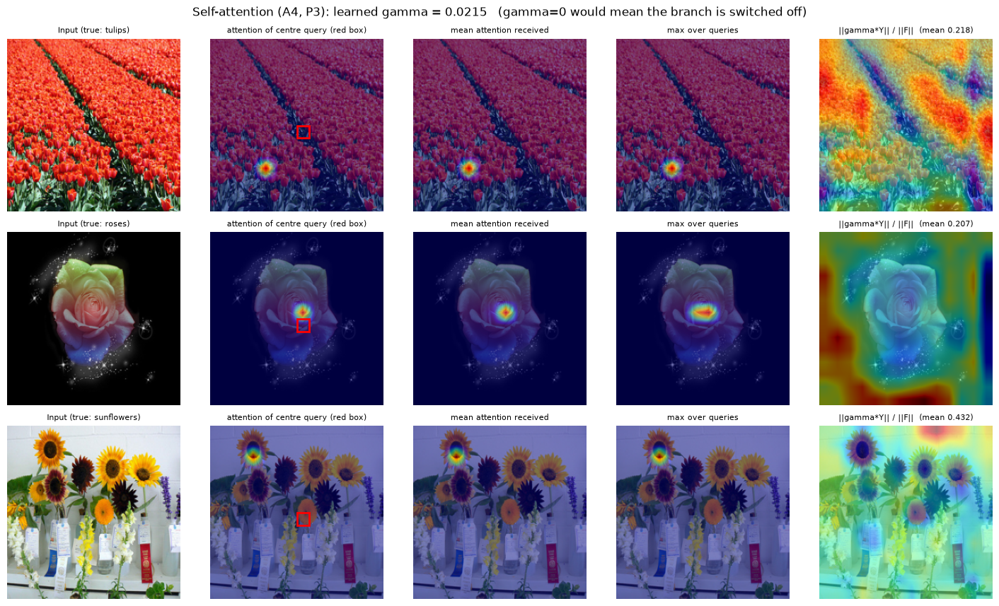

In [49]:
name, pos = "A4_Self_P3", 3; Xs = X_test[IDX_OK]
A = att_maps(name, pos, Xs, ["self"])["self"]; h = w = int(math.sqrt(A.shape[1])); qc = (h // 2) * w + (w // 2)
RESP = sa_response_ratio(name, pos, Xs)
gam = R[name]["gamma"]["att_P3"]
fig, ax = plt.subplots(len(IDX_OK), 5, figsize=(14.5, 2.9 * len(IDX_OK)))
for r, i in enumerate(IDX_OK):
    ax[r, 0].imshow(X_test[i]); ax[r, 0].set_title(f"Input (true: {CLASS_NAMES[y_test[i]]})", fontsize=8)
    q = A[r, qc].reshape(h, w); ov(ax[r, 1], i, up(norm01(q)), "attention of centre query (red box)")
    ov(ax[r, 2], i, up(norm01(A[r].mean(0).reshape(h, w))), "mean attention received")
    ov(ax[r, 3], i, up(norm01(A[r].max(0).reshape(h, w))), "max over queries")
    ov(ax[r, 4], i, up(norm01(RESP[r])), f"||gamma*Y|| / ||F||  (mean {RESP[r].mean():.3f})")
    ax[r, 1].add_patch(plt.Rectangle(((w // 2) * IMG_SIZE / w, (h // 2) * IMG_SIZE / h), IMG_SIZE / w, IMG_SIZE / h, fill=False, ec="red", lw=2))
    ax[r, 0].axis("off")
fig.suptitle(f"Self-attention (A4, P3): learned gamma = {gam:.4f}   (gamma=0 would mean the branch is switched off)"); fig.tight_layout(); show_save(fig, "fig18_self_attention_response.png")

In [50]:
# Self-attention statistics over the whole test set: locality, sharpness, contribution
def sa_stats(name, pos):
    A = att_maps(name, pos, X_test, ["self"])["self"]; N, L, _ = A.shape; h = int(math.sqrt(L))
    yy, xx = np.divmod(np.arange(L), h); D = np.sqrt((yy[:, None] - yy[None]) ** 2 + (xx[:, None] - xx[None]) ** 2)
    dist = (A * D[None]).sum(-1).mean(-1); loc = (A * (D <= 2)[None]).sum(-1).mean(-1); ent = -(A * np.log(A + 1e-12)).sum(-1).mean(-1) / np.log(L)
    resp = sa_response_ratio(name, pos, X_test)
    return {"Model": name, "gamma": round(list(R[name]["gamma"].values())[0], 4), "mean attended distance (cells)": round(float(dist.mean()), 2),
            "uniform-attention distance": round(float(D.mean()), 2), "mass within radius 2": round(float(loc.mean()), 3),
            "uniform mass within radius 2": round(float((D <= 2).mean()), 3), "row entropy (1=uniform)": round(float(ent.mean()), 3),
            "mean ||gamma Y||/||F||": round(float(resp.mean()), 4)}
SASTAT = pd.DataFrame([sa_stats(n, 3) for n in ["A4_Self_P3", "A5_Combined_P3"]]); show_table(SASTAT, "self_attention_statistics")

,Model,gamma,mean attended distance (cells),uniform-attention distance,mass within radius 2,uniform mass within radius 2,row entropy (1=uniform),mean ||gamma Y||/||F||
0,A4_Self_P3,0.0215,6.32,7.28,0.066,0.059,0.012,0.2780
1,A5_Combined_P3,-0.0210,6.41,7.28,0.066,0.059,0.056,0.3042


### 8.4 Grad-CAM comparison: baseline vs attention models (spec §27, §30, §32, §31-11/12)
Grad-CAM is computed for each model's **own predicted class** on its last feature map (7×7), upsampled to 224×224. Where a model is wrong, its heat map shows the evidence supporting its *wrong* prediction.

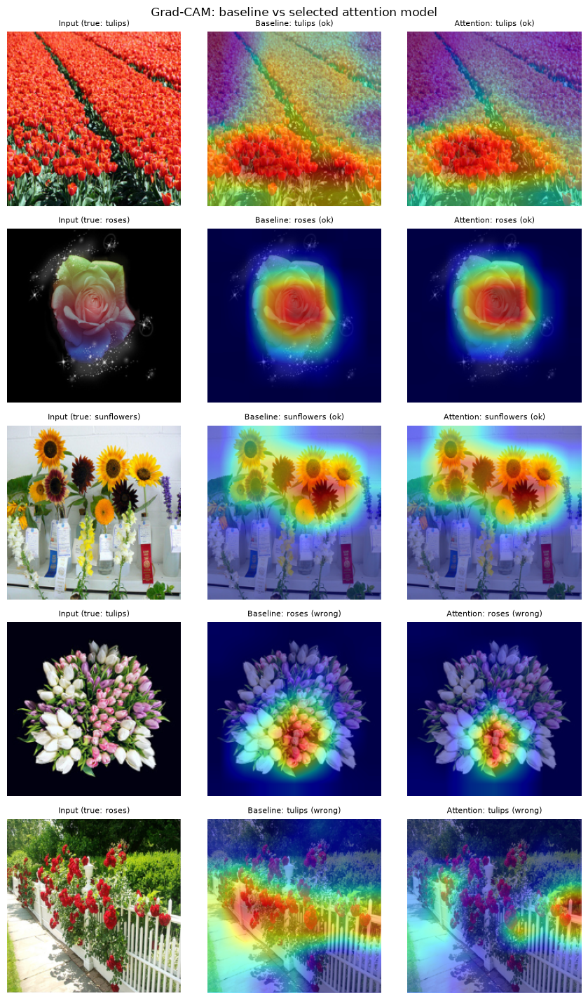

In [51]:
# §27 : Input | Baseline Grad-CAM | Selected attention model Grad-CAM
GC = {n: gradcam(n, X_test[IDX_ALL])[0] for n in _M}                                  # cached Grad-CAMs for the 5 fixed images
fig, ax = plt.subplots(len(IDX_ALL), 3, figsize=(8.8, 2.9 * len(IDX_ALL)))
for r, i in enumerate(IDX_ALL):
    ax[r, 0].imshow(X_test[i]); ax[r, 0].set_title(f"Input (true: {CLASS_NAMES[y_test[i]]})", fontsize=8); ax[r, 0].axis("off")
    ov(ax[r, 1], i, GC["A0_Baseline"][r], "Baseline: " + lab("A0_Baseline", i)); ov(ax[r, 2], i, GC[SELECTED_MODEL][r], "Attention: " + lab(SELECTED_MODEL, i))
fig.suptitle("Grad-CAM: baseline vs selected attention model"); fig.tight_layout(); show_save(fig, "fig19_gradcam_baseline_vs_selected.png")

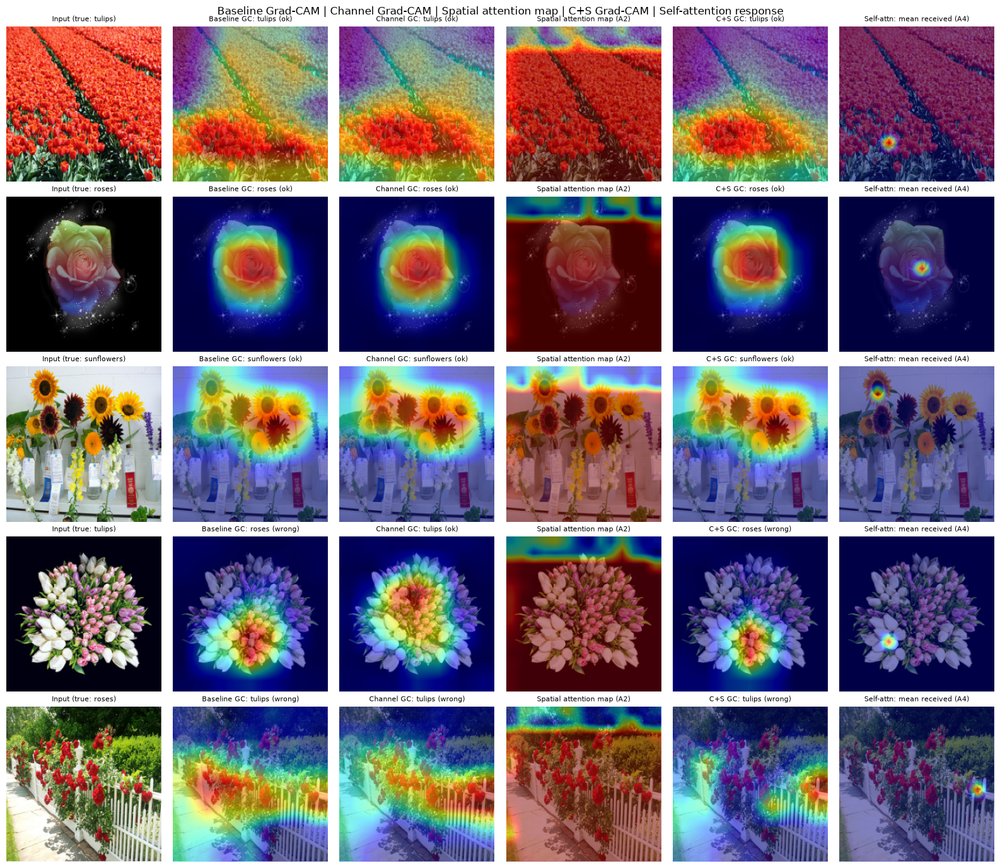

In [52]:
# §30 / §32 : Input | Baseline GC | Channel GC | Spatial attention map | C+S GC | Self-attention response   (5 fixed images)
SPm = att_maps("A2_Spatial_P3", 3, X_test[IDX_ALL], ["spatial"])["spatial"][..., 0]
SAm = att_maps("A4_Self_P3", 3, X_test[IDX_ALL], ["self"])["self"].mean(1).reshape(len(IDX_ALL), 14, 14)
fig, ax = plt.subplots(len(IDX_ALL), 6, figsize=(16, 2.8 * len(IDX_ALL)))
for r, i in enumerate(IDX_ALL):
    ax[r, 0].imshow(X_test[i]); ax[r, 0].set_title(f"Input (true: {CLASS_NAMES[y_test[i]]})", fontsize=8); ax[r, 0].axis("off")
    ov(ax[r, 1], i, GC["A0_Baseline"][r], "Baseline GC: " + lab("A0_Baseline", i)); ov(ax[r, 2], i, GC["A1_Channel_P3"][r], "Channel GC: " + lab("A1_Channel_P3", i))
    ov(ax[r, 3], i, up(norm01(SPm[r])), "Spatial attention map (A2)"); ov(ax[r, 4], i, GC["A3_CS_P3"][r], "C+S GC: " + lab("A3_CS_P3", i))
    ov(ax[r, 5], i, up(norm01(SAm[r])), "Self-attn: mean received (A4)")
fig.suptitle("Baseline Grad-CAM | Channel Grad-CAM | Spatial attention map | C+S Grad-CAM | Self-attention response"); fig.tight_layout(); show_save(fig, "fig20_gradcam_and_attention_maps_5_images.png")

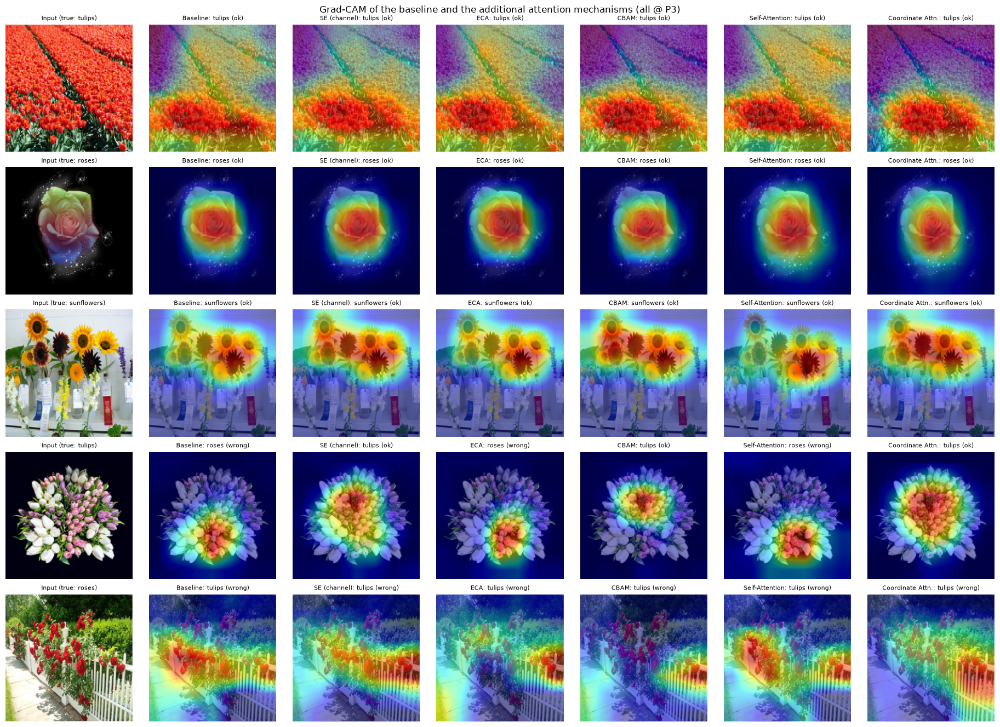

In [53]:
# §32 extended : Input | Baseline | SE | ECA | CBAM | Self-Attention | Coordinate Attention  (Grad-CAM for every model -> one consistent method)
_ex = ["A0_Baseline", "A1_Channel_P3", "X1_ECA_P3", "X2_CBAM_P3", "A4_Self_P3", "X3_Coord_P3"]; _exl = ["Baseline", "SE (channel)", "ECA", "CBAM", "Self-Attention", "Coordinate Attn."]
fig, ax = plt.subplots(len(IDX_ALL), 7, figsize=(18.5, 2.7 * len(IDX_ALL)))
for r, i in enumerate(IDX_ALL):
    ax[r, 0].imshow(X_test[i]); ax[r, 0].set_title(f"Input (true: {CLASS_NAMES[y_test[i]]})", fontsize=8); ax[r, 0].axis("off")
    for c, (n, l) in enumerate(zip(_ex, _exl), start=1): ov(ax[r, c], i, GC[n][r], f"{l}: {lab(n, i)}")
fig.suptitle("Grad-CAM of the baseline and the additional attention mechanisms (all @ P3)"); fig.tight_layout(); show_save(fig, "fig21_gradcam_additional_mechanisms.png")

In [54]:
# Whole-test-set Grad-CAM statistics (proxy metrics; spec §27 'focus', §19.2-6)
GCST = {}
for n in _M:
    st, pr = gradcam(n, X_test, stats=True); ok = pr == y_test
    f = lambda col, m: round(float(st[m, col].mean()), 3) if m.any() else float("nan")
    GCST[n] = {"Model": n, "coverage(cam>=0.5) all": f(0, np.ones(len(ok), bool)), "coverage correct": f(0, ok), "coverage wrong": f(0, ~ok),
               "norm. entropy all": f(1, np.ones(len(ok), bool)), "centre-box share all": f(2, np.ones(len(ok), bool)), "centre share correct": f(2, ok),
               "centre share wrong": f(2, ~ok), "n wrong": int((~ok).sum())}
GCSTAT = pd.DataFrame(GCST.values()); show_table(GCSTAT, "gradcam_statistics")
print("coverage = fraction of image area with Grad-CAM >= 50% of its maximum (smaller = more compact); centre-box share = Grad-CAM mass inside the central 50%x50% box (uniform = 0.25). "
      "These are proxies: tf_flowers has no foreground masks, so 'focus on the flower' cannot be measured exactly.")

,Model,coverage(cam>=0.5) all,coverage correct,coverage wrong,norm. entropy all,centre-box share all,centre share correct,centre share wrong,n wrong
0,A0_Baseline,0.245,0.251,0.153,0.952,0.459,0.463,0.383,30
1,A1_Channel_P3,0.238,0.243,0.130,0.950,0.459,0.463,0.377,26
2,A2_Spatial_P3,0.218,0.223,0.128,0.950,0.453,0.456,0.410,31
3,A3_CS_P3,0.227,0.235,0.098,0.947,0.455,0.460,0.359,31
4,A4_Self_P3,0.288,0.296,0.177,0.967,0.408,0.411,0.363,36
5,A5_Combined_P3,0.277,0.292,0.118,0.964,0.373,0.376,0.342,48
6,X1_ECA_P3,0.243,0.250,0.143,0.949,0.452,0.456,0.380,34
7,X2_CBAM_P3,0.214,0.222,0.100,0.944,0.480,0.484,0.414,36
8,X3_Coord_P3,0.321,0.328,0.214,0.966,0.422,0.425,0.387,37


coverage = fraction of image area with Grad-CAM >= 50% of its maximum (smaller = more compact); centre-box share = Grad-CAM mass inside the central 50%x50% box (uniform = 0.25). These are proxies: tf_flowers has no foreground masks, so 'focus on the flower' cannot be measured exactly.


## 9. Computed evidence for the experimental questions (spec §15–§19.2, §22, §25, §27–§29, §37)
The block below only **prints facts computed from the results above** (with their uncertainty) so that the written report can quote them. It deliberately does not claim causal explanations: with one training run per configuration, a difference is only called *distinguishable* when the paired McNemar test gives p < 0.05, and even then it comes from one seed.

In [55]:
A0 = "A0_Baseline"; acc = lambda n: R[n]["test"]["accuracy"]; f1 = lambda n: R[n]["test"]["f1"]
def sig(n1, n2):
    b, c, p = mcnemar(n1, n2); return f"p={p:.3f} ({'distinguishable' if p < 0.05 else 'NOT distinguishable'}; discordant {b}/{c})"
def line(n, ref=A0): return f"{R[n]['short']:<16} acc {pct(acc(n))}%  (d {100*(acc(n)-acc(ref)):+.2f} pp)  F1 {pct(f1(n))}%  {sig(ref, n) if n != ref else ''}"
print("=== Exp 1 / §19: attention type @ P3 (vs baseline) — ranked by test accuracy ===")
for n in sorted(_P3, key=lambda n: -acc(n)): print("  ", line(n))
print(f"  best accuracy: {R[max(_P3, key=acc)]['short']} | best macro-F1: {R[max(_P3, key=f1)]['short']}")
_ns = [n for n in _P3 if n != A0 and mcnemar(A0, n)[2] < 0.05]
print(f"  models distinguishable from baseline (McNemar p<0.05): {[R[n]['short'] for n in _ns] or 'none'}")
print("\n=== Exp 2: position of the C->S module ===")
_pos = ["B1_CS_P1", "B2_CS_P2", "A3_CS_P3", "B4_CS_P4"]
for n in _pos: print("  ", f"{R[n]['pos']}", line(n))
print(f"  best position by accuracy: {R[max(_pos, key=acc)]['pos']} | by F1: {R[max(_pos, key=f1)]['pos']} | accuracy spread across positions: {100*(max(map(acc,_pos))-min(map(acc,_pos))):.2f} pp")
print("\n=== Exp 3: multiple positions ===")
_bs = max(["A3_CS_P3", "B4_CS_P4"], key=acc)
for n in GROUPS["Exp3"]:
    print("  ", line(n, _bs).replace("(d", "(d vs best single"), f"| att params {R[n]['params_attention']:,} vs {R[_bs]['params_attention']:,}")
print("\n=== Exp 4: order ===")
print("   C->S:", line("A3_CS_P3")); print("   S->C:", line("O1_SC_P3")); print("   C->S vs S->C:", sig("A3_CS_P3", "O1_SC_P3"))
print("\n=== Exp 5: spatial kernel size ===")
for n in ["K3_CS_P3", "K5_CS_P3", "A3_CS_P3"]: print("  ", line(n), f"| {R[n]['inference_ms_bs32']:.2f} ms/img")
print("\n=== Complexity (§22) ===")
for n in _P3[1:]: print(f"   {R[n]['short']:<12} +{R[n]['params_attention']:>10,} params ({100*R[n]['params_attention']/R[A0]['params_total']:.3f}% of baseline) | time {100*(R[n]['inference_ms_bs32']/R[A0]['inference_ms_bs32']-1):+.1f}%")
print("\n=== Convergence (§19.2-5) ===")
_c = CONV.set_index("Model")
for n in _P3: print(f"   {R[n]['short']:<12} epoch(val>=90%)={_c.loc[n,'epoch val>=90%']}  best epoch={_c.loc[n,'best epoch']}  roughness={_c.loc[n,'phase-2 val-acc roughness (pp)']} pp  final gap={_c.loc[n,'final train-val acc gap (pp)']} pp")
print("\n=== Class-wise (§25): selected model vs baseline, recall change per class ===")
dr = pc(SELECTED_MODEL, "recall") - pc(A0, "recall")
print("  ", {CLASS_NAMES[c]: f"{100*dr[c]:+.1f} pp" for c in range(NUM_CLASSES)}, "| largest gain:", CLASS_NAMES[int(dr.argmax())], "| largest loss:", CLASS_NAMES[int(dr.argmin())])
print("\n=== Attention internals (§28/§29) ===")
print("   channel-weight stats:"); print(CHSTAT.to_string(index=False))
print("   spatial-map stats:"); print(SPSTAT.to_string(index=False))
print("   self-attention stats:"); print(SASTAT.to_string(index=False))
print("   Grad-CAM stats:"); print(GCSTAT.to_string(index=False))

=== Exp 1 / §19: attention type @ P3 (vs baseline) — ranked by test accuracy ===
   Channel/SE       acc 95.27%  (d +0.73 pp)  F1 95.17%  p=0.454 (NOT distinguishable; discordant 6/10)
   Baseline         acc 94.55%  (d +0.00 pp)  F1 94.59%  
   Spatial          acc 94.36%  (d -0.18 pp)  F1 94.35%  p=1.000 (NOT distinguishable; discordant 6/5)
   C+S              acc 94.36%  (d -0.18 pp)  F1 94.35%  p=1.000 (NOT distinguishable; discordant 9/8)
   ECA              acc 93.82%  (d -0.73 pp)  F1 93.74%  p=0.424 (NOT distinguishable; discordant 9/5)
   Self-Attn        acc 93.45%  (d -1.09 pp)  F1 93.42%  p=0.210 (NOT distinguishable; discordant 11/5)
   CBAM             acc 93.45%  (d -1.09 pp)  F1 93.44%  p=0.286 (NOT distinguishable; discordant 14/8)
   CoordAtt         acc 93.27%  (d -1.27 pp)  F1 93.10%  p=0.248 (NOT distinguishable; discordant 17/10)
   Combined         acc 91.27%  (d -3.27 pp)  F1 91.19%  p=0.006 (distinguishable; discordant 29/11)
  best accuracy: Channel/SE | best

## 10. Export of all outputs
Bundles the figures, tables, per-model result files and test predictions (not the large weight files) into a zip that can be downloaded and attached to the report.

In [56]:
import zipfile
zp = os.path.join(OUT_DIR, "exp8_results_bundle.zip")
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
    for d in (FIG_DIR, TAB_DIR, RES_DIR, PRED_DIR):
        for root, _, files in os.walk(d):
            for f in files: z.write(os.path.join(root, f), os.path.relpath(os.path.join(root, f), OUT_DIR))
print("Figures:"); [print("  ", f) for f in sorted(os.listdir(FIG_DIR))]
print("Tables :"); [print("  ", f) for f in sorted(os.listdir(TAB_DIR))]
print("\nBundle :", zp, f"({os.path.getsize(zp)/1e6:.1f} MB)  | model weights stay in", W_DIR)
try:
    from google.colab import files; files.download(zp)
except Exception as e: print("(download skipped:", type(e).__name__, ")")

Figures:
   fig01_sample_images.png
   fig02_accuracy_curves_exp1.png
   fig03_loss_curves_exp1.png
   fig04_convergence_selected_models.png
   fig05_attention_vs_accuracy.png
   fig06_attention_vs_macro_f1.png
   fig07_accuracy_vs_parameters.png
   fig08_f1_vs_inference_time.png
   fig09_position_and_multiposition.png
   fig10_order_and_kernel.png
   fig11_confusion_matrices.png
   fig12_feature_maps_before_after_attention.png
   fig13_channel_attention_weights.png
   fig14_spatial_attention_A2.png
   fig15_spatial_attention_A3_after_channel.png
   fig16_spatial_maps_across_positions.png
   fig17_spatial_maps_P1_to_P4.png
   fig18_self_attention_response.png
   fig19_gradcam_baseline_vs_selected.png
   fig20_gradcam_and_attention_maps_5_images.png
   fig21_gradcam_additional_mechanisms.png
Tables :
   attention_module_dimensions_all_positions.csv
   channel_weight_statistics.csv
   channel_weight_statistics.tex
   classwise_baseline_vs_selected.csv
   classwise_baseline_vs_selected.te